# Лабораторна робота №5–6
## Нейронна мережа та регуляризація

**Виконав:** Студент групи ФЕІ-45 Держко Захар  
**SEED = 47**

У роботі реалізовано повнозв'язну нейронну мережу (MLP) засобами NumPy без автоматичного диференціювання та готових реалізацій нейронних мереж. Далі досліджується вплив L1, L2, Dropout, weight clipping, gradient clipping і комбінованої регуляризації на FashionMNIST.

**Порядок виконання:** запускати комірки послідовно згори вниз. Після першого завантаження FashionMNIST датасет зберігається у локальному кеші. Якщо OpenML недоступний, у коді передбачено альтернативне завантаження через `torchvision` (за наявності цього пакета).

## План роботи та параметри експерименту

1. Завантажити FashionMNIST, перетворити кожне зображення `28 × 28` у вектор із `784` ознак та нормалізувати пікселі до `[0, 1]`.
2. Реалізувати MLP з трьома прихованими шарами, ReLU, Softmax, categorical cross-entropy, SGD і He initialization.
3. Перевірити backpropagation чисельним диференціюванням, а також зберегти та відновити навчений стан мережі.
4. Навчити базову модель та моделі з методами регуляризації на **тих самих** навчальній і валідаційній підмножинах.
5. Порівняти точність, loss, sparsity, dead neurons і розподіл ваг.

Для прискорення експериментів використовується стратифікована підмножина FashionMNIST. Розмір підмножини можна змінити в наступній комірці, але всі експерименти використовуватимуть один і той самий поділ.

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from IPython.display import display

warnings.filterwarnings('ignore')

SEED = 47
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True

print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('Pandas:', pd.__version__)
print('Seed:', SEED)

NumPy: 2.1.1
scikit-learn: 1.9.1
Pandas: 2.2.3
Seed: 47


### Етап 1. Завантаження та підготовка FashionMNIST

FashionMNIST містить зображення одягу розміром `28 × 28`. Кожне зображення розгортається у вектор довжини `784`. Значення пікселів діляться на `255`, тому належать діапазону `[0, 1]`.

Спочатку використовується `fetch_openml` зі scikit-learn. Якщо OpenML недоступний, виконується спроба завантаження через `torchvision.datasets.FashionMNIST`. Для подальшого аналізу всі мітки класів мають бути цілими числами від 0 до 9.

In [2]:
FASHION_CLASSES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]


def load_fashion_mnist():
    """Завантажує FashionMNIST через OpenML або torchvision."""
    openml_error = None

    try:
        try:
            dataset = fetch_openml(
                name='Fashion-MNIST', version=1,
                as_frame=False, parser='auto'
            )
        except TypeError:
            # Сумісність зі старішими версіями scikit-learn.
            dataset = fetch_openml(
                name='Fashion-MNIST', version=1, as_frame=False
            )

        X = np.asarray(dataset.data, dtype=np.float32)
        y = np.asarray(dataset.target).astype(np.int64)
        source = 'OpenML через scikit-learn'

    except Exception as error:
        openml_error = error
        try:
            from torchvision.datasets import FashionMNIST

            train_dataset = FashionMNIST(
                root='./data', train=True, download=True
            )
            test_dataset = FashionMNIST(
                root='./data', train=False, download=True
            )

            X = np.concatenate([
                train_dataset.data.numpy().reshape(-1, 784),
                test_dataset.data.numpy().reshape(-1, 784)
            ], axis=0).astype(np.float32)
            y = np.concatenate([
                train_dataset.targets.numpy(),
                test_dataset.targets.numpy()
            ]).astype(np.int64)
            source = 'torchvision.datasets.FashionMNIST'

        except Exception as torchvision_error:
            raise RuntimeError(
                'Не вдалося завантажити FashionMNIST. Перевірте підключення '
                'до Інтернету або доступність локального кешу OpenML/torchvision. '
                f'Помилка OpenML: {openml_error}. '
                f'Помилка torchvision: {torchvision_error}.'
            )

    if X.ndim > 2:
        X = X.reshape(X.shape[0], -1)

    if X.shape[1] != 784:
        raise ValueError(
            f'Очікувалося 784 ознаки на зображення, отримано {X.shape[1]}.'
        )

    if X.max() > 1.0:
        X = X / 255.0

    X = np.clip(X, 0.0, 1.0).astype(np.float32)
    y = y.astype(np.int64)

    if not np.array_equal(np.unique(y), np.arange(10)):
        raise ValueError('Очікуються мітки FashionMNIST від 0 до 9.')

    return X, y, source


X_all, y_all, DATA_SOURCE = load_fashion_mnist()

print('Джерело даних:', DATA_SOURCE)
print('Кількість зображень:', X_all.shape[0])
print('Кількість ознак:', X_all.shape[1])
print('Діапазон пікселів:', (float(X_all.min()), float(X_all.max())))
print('Кількість класів:', len(np.unique(y_all)))

Джерело даних: OpenML через scikit-learn
Кількість зображень: 70000
Кількість ознак: 784
Діапазон пікселів: (0.0, 1.0)
Кількість класів: 10


Розмір тренувальної підмножини: (5000, 784)
Розмір валідаційної підмножини: (1000, 784)

Розподіл класів у train:


,Кількість
T-shirt/top,500
Trouser,500
Pullover,500
Dress,500
Coat,500
Sandal,500
Shirt,500
Sneaker,500
Bag,500
Ankle boot,500


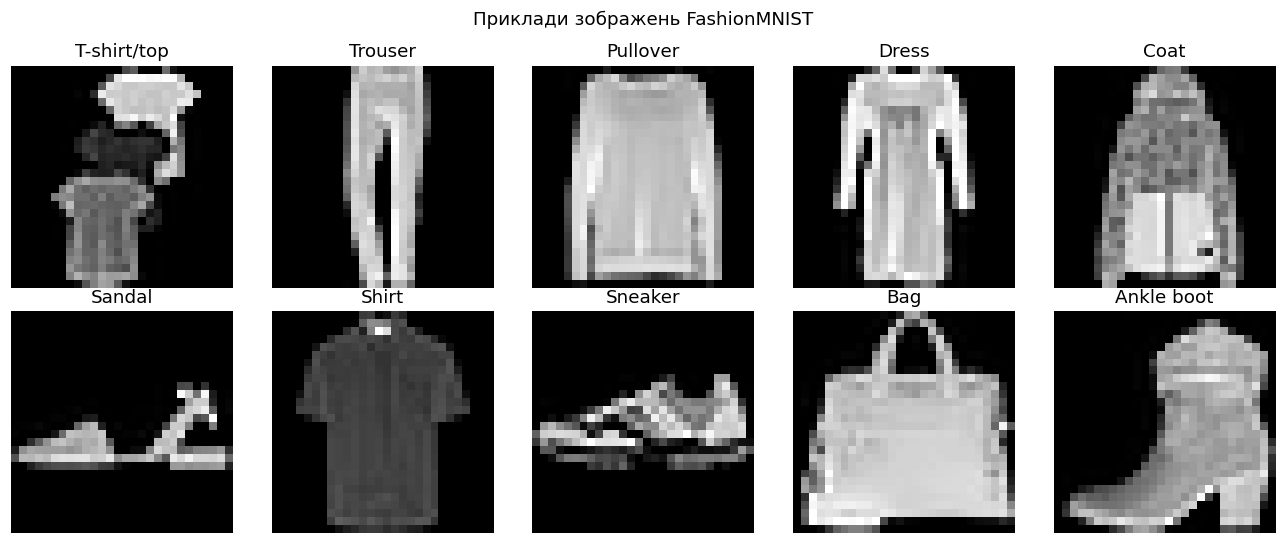

In [3]:
# Спочатку відокремлюємо валідаційну частину зі стратифікацією за класами.
X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(
    X_all, y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all
)

# Ліміти можна збільшити за наявності достатніх обчислювальних ресурсів.
TRAIN_SAMPLES = 5000
VAL_SAMPLES = 1000


def stratified_subset(X, y, n_samples, random_state):
    """Повертає однакову за змістом стратифіковану підмножину для всіх запусків."""
    if n_samples is None or n_samples >= len(X):
        return X.copy(), y.copy()
    X_part, _, y_part, _ = train_test_split(
        X, y,
        train_size=n_samples,
        random_state=random_state,
        stratify=y
    )
    return X_part, y_part


X_train, y_train = stratified_subset(
    X_train_full, y_train_full, TRAIN_SAMPLES, SEED + 1
)
X_val, y_val = stratified_subset(
    X_val_full, y_val_full, VAL_SAMPLES, SEED + 2
)

print('Розмір тренувальної підмножини:', X_train.shape)
print('Розмір валідаційної підмножини:', X_val.shape)
print('\nРозподіл класів у train:')
display(pd.Series(y_train).value_counts().sort_index().rename(index=dict(enumerate(FASHION_CLASSES))).to_frame('Кількість'))

# Візуалізація кількох прикладів зображень.
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    index = np.where(y_train == class_id)[0][0]
    ax.imshow(X_train[index].reshape(28, 28), cmap='gray')
    ax.set_title(FASHION_CLASSES[class_id])
    ax.axis('off')
plt.suptitle('Приклади зображень FashionMNIST')
plt.tight_layout()
plt.show()

## Блок 1. Реалізація нейронної мережі з нуля

### Етап 2. Архітектура та прямий прохід

Використовується архітектура:

`784 → 128 → 64 → 32 → 10`

Отже, мережа має три приховані шари. Для кожного шару обчислюється

\[
Z^{(l)} = A^{(l-1)}W^{(l)} + b^{(l)}, \qquad
A^{(l)} = \operatorname{ReLU}(Z^{(l)}).
\]

На вихідному шарі застосовується Softmax. Ваги ініціалізуються методом He:

\[
W_{ij}^{(l)} \sim \mathcal{N}\left(0, \frac{2}{n_{in}}\right).
\]

Клас зберігає матриці ваг, вектори зміщень, проміжні `Z` та `A`, архітектуру й параметри ініціалізації.

In [4]:
class MLP:
    """Повнозв'язна MLP з ручними forward/backward та SGD на NumPy."""

    def __init__(self, architecture, seed=SEED, init_method='he', dtype='float32'):
        self.architecture = tuple(int(value) for value in architecture)
        self.seed = int(seed)
        self.init_method = str(init_method)
        self.dtype = np.dtype(dtype)

        if len(self.architecture) < 3:
            raise ValueError('Потрібні вхідний, хоча б один прихований та вихідний шари.')
        if self.init_method != 'he':
            raise ValueError('У цій роботі основною ініціалізацією є He.')

        self.rng_init = np.random.default_rng(self.seed)
        self.rng_dropout = np.random.default_rng(self.seed + 1)

        self.weights = []
        self.biases = []
        for fan_in, fan_out in zip(self.architecture[:-1], self.architecture[1:]):
            std = np.sqrt(2.0 / fan_in)
            W = self.rng_init.normal(0.0, std, size=(fan_in, fan_out))
            self.weights.append(W.astype(self.dtype))
            self.biases.append(np.zeros(fan_out, dtype=self.dtype))

        self.activations = []
        self.z_values = []
        self.dropout_masks = []
        self.last_training_config = {}

    def forward(self, X, training=False, dropout_p=0.0):
        """Повертає ймовірності класів; Dropout активний лише під час навчання."""
        A = np.asarray(X, dtype=self.dtype)
        self.activations = [A]
        self.z_values = []
        self.dropout_masks = []

        # Приховані шари: affine -> ReLU -> inverted Dropout (за потреби).
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0.0, Z)
            self.z_values.append(Z)

            if training and dropout_p > 0.0:
                mask = (
                    self.rng_dropout.random(A.shape) >= dropout_p
                ).astype(self.dtype) / (1.0 - dropout_p)
                A = A * mask
            else:
                mask = None

            self.dropout_masks.append(mask)
            self.activations.append(A)

        # Вихідний шар: Softmax зі стабілізацією відніманням максимуму.
        Z = A @ self.weights[-1] + self.biases[-1]
        Z_stable = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_stable)
        probabilities = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

        self.z_values.append(Z)
        self.activations.append(probabilities)
        return probabilities

    @staticmethod
    def cross_entropy(probabilities, y_true):
        y_true = np.asarray(y_true, dtype=np.int64)
        correct_probabilities = probabilities[np.arange(len(y_true)), y_true]
        return float(-np.mean(np.log(np.clip(correct_probabilities, 1e-12, 1.0))))

    def backward(self, y_true, lambda_l1=0.0, lambda_l2=0.0):
        """Ручний backpropagation для Softmax + CE + L1/L2."""
        y_true = np.asarray(y_true, dtype=np.int64)
        n = y_true.shape[0]
        num_layers = len(self.weights)

        grads_W = [None] * num_layers
        grads_b = [None] * num_layers

        # dL/dZ для Softmax разом із categorical cross-entropy.
        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1.0
        delta /= n

        for layer_index in reversed(range(num_layers)):
            A_prev = self.activations[layer_index]
            grads_W[layer_index] = A_prev.T @ delta
            grads_b[layer_index] = np.sum(delta, axis=0)

            # Поширення градієнта до попереднього прихованого шару.
            if layer_index > 0:
                delta = delta @ self.weights[layer_index].T

                # Похідна inverted Dropout (маска вже містить множник 1/(1-p)).
                dropout_mask = self.dropout_masks[layer_index - 1]
                if dropout_mask is not None:
                    delta *= dropout_mask

                # Похідна ReLU: 1 для Z > 0, інакше 0.
                delta *= (self.z_values[layer_index - 1] > 0.0)

        # Субградієнт L1 у нулі дорівнює 0; L2 додає lambda * W.
        for layer_index in range(num_layers):
            if lambda_l1:
                grads_W[layer_index] += lambda_l1 * np.sign(self.weights[layer_index])
            if lambda_l2:
                grads_W[layer_index] += lambda_l2 * self.weights[layer_index]

        return grads_W, grads_b

    def regularization_penalty(self, lambda_l1=0.0, lambda_l2=0.0):
        l1_sum = sum(np.sum(np.abs(W), dtype=np.float64) for W in self.weights)
        l2_sum = sum(np.sum(W * W, dtype=np.float64) for W in self.weights)
        return float(lambda_l1 * l1_sum + 0.5 * lambda_l2 * l2_sum)

    @staticmethod
    def global_gradient_norm(grads_W, grads_b):
        squared_sum = 0.0
        for gradient in grads_W + grads_b:
            squared_sum += np.sum(gradient.astype(np.float64) ** 2)
        return float(np.sqrt(squared_sum))

    def predict_proba(self, X, batch_size=512):
        X = np.asarray(X, dtype=self.dtype)
        probabilities = []
        for start in range(0, len(X), batch_size):
            batch = X[start:start + batch_size]
            probabilities.append(self.forward(batch, training=False))
        return np.vstack(probabilities)

    def predict(self, X, batch_size=512):
        return np.argmax(self.predict_proba(X, batch_size=batch_size), axis=1)

    def evaluate(self, X, y):
        probabilities = self.predict_proba(X)
        return {
            'loss': self.cross_entropy(probabilities, y),
            'accuracy': float(np.mean(np.argmax(probabilities, axis=1) == y))
        }

    def fit(
        self, X_train, y_train, X_val, y_val,
        epochs=5, batch_size=256, learning_rate=0.1,
        lambda_l1=0.0, lambda_l2=0.0, dropout_p=0.0,
        weight_clip=None, gradient_clip=None, verbose=True
    ):
        """Мінібатчеве навчання SGD; жодних автодиференціювання чи готових оптимізаторів."""
        X_train = np.asarray(X_train, dtype=self.dtype)
        X_val = np.asarray(X_val, dtype=self.dtype)
        y_train = np.asarray(y_train, dtype=np.int64)
        y_val = np.asarray(y_val, dtype=np.int64)

        if not 0.0 <= dropout_p < 1.0:
            raise ValueError('dropout_p має належати [0, 1).')

        self.last_training_config = {
            'epochs': int(epochs),
            'batch_size': int(batch_size),
            'learning_rate': float(learning_rate),
            'lambda_l1': float(lambda_l1),
            'lambda_l2': float(lambda_l2),
            'dropout_p': float(dropout_p),
            'weight_clip': None if weight_clip is None else float(weight_clip),
            'gradient_clip': None if gradient_clip is None else float(gradient_clip)
        }

        history = {
            'train_loss': [], 'val_loss': [],
            'train_accuracy': [], 'val_accuracy': [],
            'mean_gradient_norm': [], 'clipped_batches': []
        }
        shuffle_rng = np.random.default_rng(self.seed + 2)

        for epoch in range(epochs):
            order = shuffle_rng.permutation(len(X_train))
            clipped_batches = 0
            gradient_norms = []

            for start in range(0, len(order), batch_size):
                batch_indices = order[start:start + batch_size]
                X_batch = X_train[batch_indices]
                y_batch = y_train[batch_indices]

                self.forward(X_batch, training=True, dropout_p=dropout_p)
                grads_W, grads_b = self.backward(
                    y_batch, lambda_l1=lambda_l1, lambda_l2=lambda_l2
                )

                gradient_norm = self.global_gradient_norm(grads_W, grads_b)
                gradient_norms.append(gradient_norm)

                # Глобальне обрізання норми всього вектора градієнтів.
                if gradient_clip is not None and gradient_norm > gradient_clip:
                    scale = gradient_clip / (gradient_norm + 1e-12)
                    grads_W = [gradient * scale for gradient in grads_W]
                    grads_b = [gradient * scale for gradient in grads_b]
                    clipped_batches += 1

                # Звичайний SGD для всіх матриць ваг і векторів зміщень.
                for layer_index in range(len(self.weights)):
                    self.weights[layer_index] -= learning_rate * grads_W[layer_index]
                    self.biases[layer_index] -= learning_rate * grads_b[layer_index]

                    # Weight clipping застосовується після кожного кроку оновлення ваг.
                    if weight_clip is not None:
                        self.weights[layer_index] = np.clip(
                            self.weights[layer_index], -weight_clip, weight_clip
                        )

            train_metrics = self.evaluate(X_train, y_train)
            val_metrics = self.evaluate(X_val, y_val)
            train_objective = train_metrics['loss'] + self.regularization_penalty(
                lambda_l1=lambda_l1, lambda_l2=lambda_l2
            )

            history['train_loss'].append(float(train_objective))
            history['val_loss'].append(float(val_metrics['loss']))
            history['train_accuracy'].append(train_metrics['accuracy'])
            history['val_accuracy'].append(val_metrics['accuracy'])
            history['mean_gradient_norm'].append(float(np.mean(gradient_norms)))
            history['clipped_batches'].append(int(clipped_batches))

            if verbose:
                print(
                    f'Epoch {epoch + 1:02d}/{epochs}: '
                    f'train objective={train_objective:.4f}, '
                    f'val loss={val_metrics["loss"]:.4f}, '
                    f'train acc={train_metrics["accuracy"]:.4f}, '
                    f'val acc={val_metrics["accuracy"]:.4f}'
                )

        return history

    def save_weights(self, path):
        """Зберігає ваги, biases, архітектуру, ініціалізацію та конфігурацію."""
        metadata = {
            'architecture': list(self.architecture),
            'seed': self.seed,
            'init_method': self.init_method,
            'dtype': self.dtype.name,
            'last_training_config': self.last_training_config
        }
        arrays = {'metadata_json': np.array(json.dumps(metadata))}
        for i, W in enumerate(self.weights):
            arrays[f'W_{i}'] = W
        for i, b in enumerate(self.biases):
            arrays[f'b_{i}'] = b
        np.savez_compressed(path, **arrays)

    def load_weights(self, path):
        """Завантажує ваги у сумісний екземпляр MLP."""
        with np.load(path, allow_pickle=False) as data:
            metadata = json.loads(str(data['metadata_json'].item()))
            saved_architecture = tuple(metadata['architecture'])
            if saved_architecture != self.architecture:
                raise ValueError(
                    f'Архітектура файлу {saved_architecture} не збігається '
                    f'з архітектурою моделі {self.architecture}.'
                )
            self.weights = [
                data[f'W_{i}'].astype(self.dtype, copy=True)
                for i in range(len(self.architecture) - 1)
            ]
            self.biases = [
                data[f'b_{i}'].astype(self.dtype, copy=True)
                for i in range(len(self.architecture) - 1)
            ]
            self.last_training_config = metadata.get('last_training_config', {})
        return self

    @classmethod
    def from_file(cls, path):
        """Створює новий MLP з архітектурою з файлу та відновлює його параметри."""
        with np.load(path, allow_pickle=False) as data:
            metadata = json.loads(str(data['metadata_json'].item()))
        model = cls(
            architecture=metadata['architecture'],
            seed=metadata['seed'],
            init_method=metadata['init_method'],
            dtype=metadata['dtype']
        )
        model.load_weights(path)
        return model


ARCHITECTURE = [784, 128, 64, 32, 10]
print('Архітектура MLP:', ' → '.join(map(str, ARCHITECTURE)))
print('Прихованих шарів:', len(ARCHITECTURE) - 2)

Архітектура MLP: 784 → 128 → 64 → 32 → 10
Прихованих шарів: 3


### Етап 3. Перевірка backpropagation чисельним диференціюванням

Для декількох параметрів порівнюється аналітичний градієнт з центральною скінченно-різницевою оцінкою:

\[
 g_{num} \approx \frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon},
 \qquad
 E=\frac{|g_{analytic}-g_{numeric}|}
 {\max(10^{-8}, |g_{analytic}|+|g_{numeric}|)}.
\]

Для перевірки використовується невелика мережа з тією самою кількістю прихованих шарів, але малою кількістю входів і нейронів. Це пришвидшує чисельне диференціювання. Для цієї перевірки використовується `float64`, щоб зменшити похибку округлення.

In [5]:
# Градієнт-чек на невеликій мережі: 3 приховані шари, 3 класи.
rng_check = np.random.default_rng(SEED)
X_check = rng_check.normal(size=(5, 4)).astype(np.float64)
y_check = np.array([0, 2, 1, 2, 0], dtype=np.int64)
check_model = MLP([4, 6, 5, 4, 3], seed=SEED, dtype='float64')

P_check = check_model.forward(X_check, training=False)
analytic_W, analytic_b = check_model.backward(y_check)

epsilon = 1e-5
parameters = []
for layer_index in range(len(check_model.weights)):
    parameters.append(('W', layer_index, (0, 0)))
    parameters.append(('W', layer_index, (1, min(1, check_model.weights[layer_index].shape[1] - 1))))
    parameters.append(('b', layer_index, (0,)))

# Вибираємо кілька параметрів із різних шарів.
selected_parameters = parameters[:]
rng_check.shuffle(selected_parameters)
selected_parameters = selected_parameters[:9]
check_rows = []


def check_loss():
    probabilities = check_model.forward(X_check, training=False)
    return check_model.cross_entropy(probabilities, y_check)


for kind, layer_index, index in selected_parameters:
    array = check_model.weights[layer_index] if kind == 'W' else check_model.biases[layer_index]
    analytic_array = analytic_W[layer_index] if kind == 'W' else analytic_b[layer_index]
    analytic_value = float(analytic_array[index])
    original_value = float(array[index])

    array[index] = original_value + epsilon
    loss_plus = check_loss()
    array[index] = original_value - epsilon
    loss_minus = check_loss()
    array[index] = original_value

    numeric_value = (loss_plus - loss_minus) / (2.0 * epsilon)
    relative_error = abs(analytic_value - numeric_value) / max(
        1e-8, abs(analytic_value) + abs(numeric_value)
    )

    check_rows.append({
        'Parameter': kind,
        'Layer': layer_index + 1,
        'Index': str(index),
        'Analytical gradient': analytic_value,
        'Numerical gradient': numeric_value,
        'Relative error': relative_error
    })

gradient_check_df = pd.DataFrame(check_rows)
display(gradient_check_df)
print('Максимальна відносна похибка:', gradient_check_df['Relative error'].max())
assert gradient_check_df['Relative error'].max() < 1e-5, 'Перевірка градієнтів не пройдена.'
print('Перевірка градієнтів пройдена: відносна похибка для вибраних параметрів менша за 1e-5.')

,Parameter,Layer,Index,Analytical gradient,Numerical gradient,Relative error
0,W,1,"(1, 1)",-0.084231,-0.084231,6.869930e-11
1,b,4,"(0,)",-0.141739,-0.141739,4.127858e-11
2,b,3,"(0,)",-0.014043,-0.014043,5.249512e-11
3,W,3,"(0, 0)",-0.018216,-0.018216,1.863446e-10
4,W,1,"(0, 0)",-0.070918,-0.070918,6.955034e-11
5,W,2,"(1, 1)",0.110254,0.110254,9.232319e-12
6,b,2,"(0,)",-0.006408,-0.006408,4.186057e-10
7,W,2,"(0, 0)",0.000000,0.000000,0.000000e+00
8,W,4,"(0, 0)",-0.001501,-0.001501,8.486844e-10


Максимальна відносна похибка: 8.486844035066217e-10
Перевірка градієнтів пройдена: відносна похибка для вибраних параметрів менша за 1e-5.


### Етап 4. Навчання базової моделі

Базова модель не використовує жодного методу регуляризації. Для оновлення ваг і зміщень використовується SGD:

\[
W^{(l)} \leftarrow W^{(l)}-\eta\nabla_{W^{(l)}}L,\qquad
b^{(l)} \leftarrow b^{(l)}-\eta\nabla_{b^{(l)}}L.
\]

Усі наступні моделі матимуть однакову архітектуру, початкову ініціалізацію (за тим самим seed), поділ даних, кількість епох і розмір мінібатча. Це дозволяє порівнювати саме вплив методу регуляризації.

In [6]:
EPOCHS = 5
BATCH_SIZE = 256
LEARNING_RATE = 0.1

# Фіксуємо початковий розподіл He до будь-якого навчання.
initial_model = MLP(ARCHITECTURE, seed=SEED)
initial_weights = [W.copy() for W in initial_model.weights]

baseline_model = initial_model
baseline_history = baseline_model.fit(
    X_train, y_train, X_val, y_val,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    verbose=True
)

baseline_train_metrics = baseline_model.evaluate(X_train, y_train)
baseline_val_metrics = baseline_model.evaluate(X_val, y_val)
print('\nБазова модель:')
print(f"Train accuracy: {baseline_train_metrics['accuracy']:.4f}")
print(f"Validation accuracy: {baseline_val_metrics['accuracy']:.4f}")
print(f"Validation loss: {baseline_val_metrics['loss']:.4f}")

Epoch 01/5: train objective=1.2458, val loss=1.2239, train acc=0.5986, val acc=0.5970
Epoch 02/5: train objective=1.1385, val loss=1.0971, train acc=0.6204, val acc=0.6560
Epoch 03/5: train objective=0.8312, val loss=0.8045, train acc=0.6928, val acc=0.7040
Epoch 04/5: train objective=0.6475, val loss=0.6189, train acc=0.7610, val acc=0.7810
Epoch 05/5: train objective=0.7074, val loss=0.6975, train acc=0.7264, val acc=0.7360

Базова модель:
Train accuracy: 0.7264
Validation accuracy: 0.7360
Validation loss: 0.6975


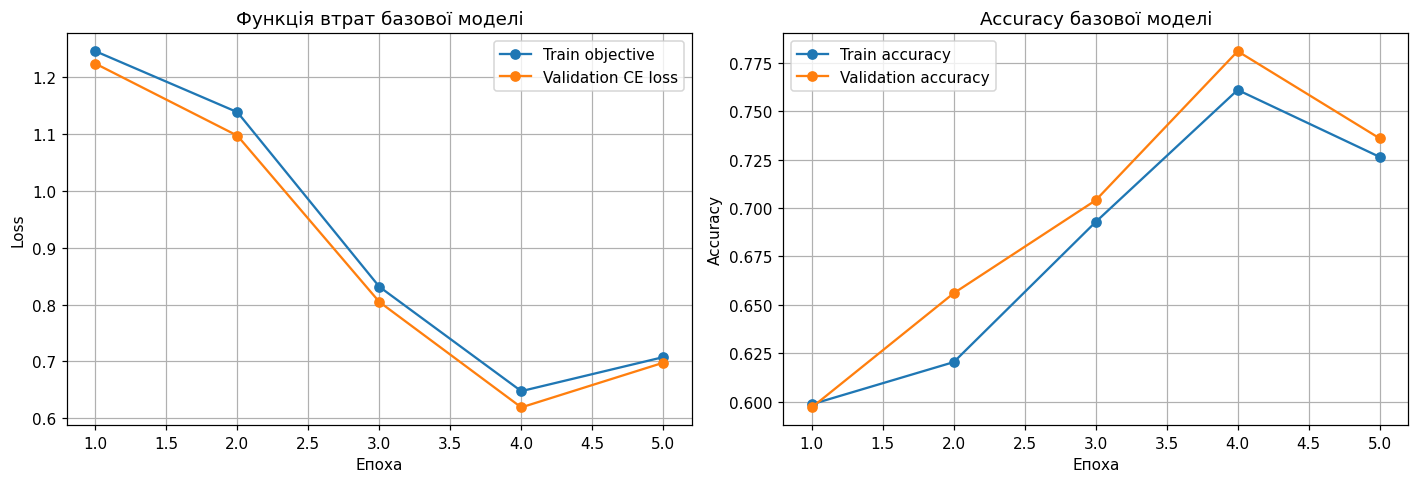

Пояснення: train objective для регуляризованих моделей включатиме штраф, а validation CE loss обчислюється без Dropout і без додавання штрафу. Для базової моделі штраф дорівнює нулю.


In [7]:
# Графіки функції втрат та accuracy для тренувальної і валідаційної вибірок.
epoch_numbers = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epoch_numbers, baseline_history['train_loss'], marker='o', label='Train objective')
axes[0].plot(epoch_numbers, baseline_history['val_loss'], marker='o', label='Validation CE loss')
axes[0].set_title('Функція втрат базової моделі')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epoch_numbers, baseline_history['train_accuracy'], marker='o', label='Train accuracy')
axes[1].plot(epoch_numbers, baseline_history['val_accuracy'], marker='o', label='Validation accuracy')
axes[1].set_title('Accuracy базової моделі')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

print(
    'Пояснення: train objective для регуляризованих моделей включатиме штраф, '
    'а validation CE loss обчислюється без Dropout і без додавання штрафу. '
    'Для базової моделі штраф дорівнює нулю.'
)

### Етап 5. Збереження та відновлення ваг

У файл записуються всі `W`, `b`, архітектура, seed, метод ініціалізації, тип даних і конфігурація останнього навчання. Після цього створюється **новий** екземпляр MLP та відновлюються його параметри.

Критерій коректності з PDF:

\[
\max |P_{original}-P_{restored}| < 10^{-7}.
\]

In [8]:
MODEL_PATH = 'fashion_mnist_mlp_weights.npz'
baseline_model.save_weights(MODEL_PATH)
restored_model = MLP.from_file(MODEL_PATH)

probabilities_original = baseline_model.predict_proba(X_val[:64])
probabilities_restored = restored_model.predict_proba(X_val[:64])
max_probability_difference = float(
    np.max(np.abs(probabilities_original - probabilities_restored))
)
predictions_original = np.argmax(probabilities_original, axis=1)
predictions_restored = np.argmax(probabilities_restored, axis=1)

print('Файл збереження:', MODEL_PATH)
print('Архітектура відновленої моделі:', restored_model.architecture)
print('Максимальна різниця ймовірностей:', max_probability_difference)
print('Передбачені класи повністю збігаються:', np.array_equal(predictions_original, predictions_restored))
assert max_probability_difference < 1e-7
assert np.array_equal(predictions_original, predictions_restored)
print('Збереження та відновлення перевірено успішно.')

Файл збереження: fashion_mnist_mlp_weights.npz
Архітектура відновленої моделі: (784, 128, 64, 32, 10)
Максимальна різниця ймовірностей: 0.0
Передбачені класи повністю збігаються: True
Збереження та відновлення перевірено успішно.


## Блок 2. Дослідження впливу регуляризації

### Етап 6. Метрики та діагностика dead neurons

Нейрон прихованого шару вважається мертвим на досліджуваній тренувальній підмножині, якщо його передактивація не була додатною **для жодного** об'єкта цієї підмножини:

\[
\max_i Z_{ij}^{(l)} \leq 0.
\]

Частка мертвих нейронів шару дорівнює `N_dead / N_neurons × 100%`. Перевірка виконується в режимі inference: Dropout вимкнений.

Sparsity ваг обчислюється за формулою з PDF:

\[
S=\frac{\#\{|W_{ij}|<0.01\}}{\#\{W_{ij}\}}\cdot100\%.
\]

In [9]:
def calculate_sparsity(model, threshold=0.01):
    all_weights = np.concatenate([W.ravel() for W in model.weights])
    return float(np.mean(np.abs(all_weights) < threshold) * 100.0)


def diagnose_dead_neurons(model, X, batch_size=512):
    """Рахує dead neurons на всьому X у режимі inference (Dropout вимкнений)."""
    hidden_sizes = model.architecture[1:-1]
    active_anywhere = [np.zeros(size, dtype=bool) for size in hidden_sizes]

    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size]
        model.forward(batch, training=False, dropout_p=0.0)
        for layer_index, Z in enumerate(model.z_values[:-1]):
            active_anywhere[layer_index] |= np.any(Z > 0.0, axis=0)

    rows = []
    for layer_index, size in enumerate(hidden_sizes):
        dead_count = int(np.sum(~active_anywhere[layer_index]))
        rows.append({
            'Hidden layer': f'H{layer_index + 1}',
            'Dead neurons': dead_count,
            'Total neurons': int(size),
            'Dead neurons, %': dead_count / size * 100.0
        })
    return pd.DataFrame(rows)


def count_weights_at_clip_boundaries(model, bound=1.0, tolerance=1e-6):
    count = 0
    for W in model.weights:
        count += int(np.sum(np.abs(np.abs(W) - bound) <= tolerance))
    return count


def summarize_model(model, history, X_train, y_train, X_val, y_val, config):
    train_metrics = model.evaluate(X_train, y_train)
    val_metrics = model.evaluate(X_val, y_val)
    dead_table = diagnose_dead_neurons(model, X_train)
    total_dead = int(dead_table['Dead neurons'].sum())
    total_hidden = int(dead_table['Total neurons'].sum())

    return {
        'model': model,
        'history': history,
        'train_accuracy': train_metrics['accuracy'],
        'train_loss': train_metrics['loss'],
        'val_accuracy': val_metrics['accuracy'],
        'val_loss': val_metrics['loss'],
        'sparsity': calculate_sparsity(model),
        'dead_table': dead_table,
        'dead_count': total_dead,
        'hidden_count': total_hidden,
        'dead_pct': total_dead / total_hidden * 100.0,
        'weights_at_bounds': count_weights_at_clip_boundaries(model),
        'config': dict(config)
    }


def run_experiment(name, **config):
    model = MLP(ARCHITECTURE, seed=SEED)
    history = model.fit(
        X_train, y_train, X_val, y_val,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        verbose=False,
        **config
    )
    result = summarize_model(
        model, history, X_train, y_train, X_val, y_val, config
    )
    print(
        f'{name}: val_accuracy={result["val_accuracy"]:.4f}, '
        f'val_loss={result["val_loss"]:.4f}, '
        f'dead={result["dead_pct"]:.2f}%, '
        f'sparsity={result["sparsity"]:.2f}%'
    )
    return result


# Результат базової моделі додаємо до спільного словника.
results = {
    'Без регуляризації': summarize_model(
        baseline_model,
        baseline_history,
        X_train, y_train, X_val, y_val,
        config={}
    )
}

### Етап 7. L2 regularization

Для L2 використовується штраф

\[
L=L_{CE}+\frac{\lambda_2}{2}\sum_l\|W^{(l)}\|_2^2,
\]

тому до градієнта кожної матриці ваг додається `lambda_2 * W`. Перевіряються три значення коефіцієнта: `1e-4`, `5e-4`, `1e-3`. Валідаційна точність і розподіл ваг будуть порівняні з базовою моделлю.

In [10]:
L2_VALUES = [1e-4, 5e-4, 1e-3]
l2_experiment_names = []

for lambda_2 in L2_VALUES:
    name = f'L2 (lambda={lambda_2:g})'
    results[name] = run_experiment(name, lambda_l2=lambda_2)
    l2_experiment_names.append(name)

l2_best_name = max(
    l2_experiment_names,
    key=lambda name: results[name]['val_accuracy']
)
L2_SELECTED = results[l2_best_name]['config']['lambda_l2']
print('\nВибраний коефіцієнт L2 за валідаційною accuracy:', L2_SELECTED)

L2 (lambda=0.0001): val_accuracy=0.7690, val_loss=0.6752, dead=0.45%, sparsity=14.46%
L2 (lambda=0.0005): val_accuracy=0.7130, val_loss=0.7742, dead=0.45%, sparsity=14.59%
L2 (lambda=0.001): val_accuracy=0.7280, val_loss=0.7263, dead=0.89%, sparsity=14.65%

Вибраний коефіцієнт L2 за валідаційною accuracy: 0.0001


### Етап 8. L1 regularization

L1 додає до функції втрат суму абсолютних значень ваг:

\[
L=L_{CE}+\lambda_1\sum_l\|W^{(l)}\|_1,
\qquad
\frac{\partial L_{reg}}{\partial W^{(l)}}=\lambda_1\operatorname{sign}(W^{(l)}).
\]

У точці нуля використовується субградієнт `0`, що реалізовано через `np.sign`. Перевіряються три значення `lambda_1`.

In [11]:
L1_VALUES = [5e-6, 2e-5, 5e-5]
l1_experiment_names = []

for lambda_1 in L1_VALUES:
    name = f'L1 (lambda={lambda_1:g})'
    results[name] = run_experiment(name, lambda_l1=lambda_1)
    l1_experiment_names.append(name)

l1_best_name = max(
    l1_experiment_names,
    key=lambda name: results[name]['val_accuracy']
)
L1_SELECTED = results[l1_best_name]['config']['lambda_l1']
print('\nВибраний коефіцієнт L1 за валідаційною accuracy:', L1_SELECTED)

L1 (lambda=5e-06): val_accuracy=0.7370, val_loss=0.7046, dead=0.45%, sparsity=14.57%
L1 (lambda=2e-05): val_accuracy=0.7180, val_loss=0.7278, dead=0.45%, sparsity=14.80%
L1 (lambda=5e-05): val_accuracy=0.7350, val_loss=0.7107, dead=0.45%, sparsity=15.18%

Вибраний коефіцієнт L1 за валідаційною accuracy: 5e-06


### Етап 9. Dropout

Під час навчання кожна прихована активація множиться на випадкову маску Bernoulli, а за inverted Dropout — ділиться на `1-p`. Під час оцінювання маска не застосовується.

Обов'язкові значення: `p ∈ {0.1, 0.3, 0.5}`. Додатково запускається `p=0.2`, щоб коректно порівняти комбінований варіант `L2 + Dropout 0.2` з окремим Dropout тієї самої інтенсивності.

In [12]:
DROPOUT_VALUES = [0.1, 0.2, 0.3, 0.5]
dropout_experiment_names = {}

for dropout_p in DROPOUT_VALUES:
    name = f'Dropout (p={dropout_p:.1f})'
    results[name] = run_experiment(name, dropout_p=dropout_p)
    dropout_experiment_names[dropout_p] = name

Dropout (p=0.1): val_accuracy=0.7880, val_loss=0.6434, dead=0.45%, sparsity=14.53%
Dropout (p=0.2): val_accuracy=0.7790, val_loss=0.7073, dead=0.45%, sparsity=14.54%
Dropout (p=0.3): val_accuracy=0.7340, val_loss=0.7664, dead=0.00%, sparsity=14.57%
Dropout (p=0.5): val_accuracy=0.6550, val_loss=1.2527, dead=0.00%, sparsity=14.63%


### Етап 10. Weight clipping

Після кожного кроку SGD кожна матриця ваг обмежується інтервалом `[-1, 1]`:

\[
W^{(l)}\leftarrow\operatorname{clip}(W^{(l)},-1,1).
\]

Окрім якості класифікації, буде підраховано кількість ваг, що досягли меж `-1` або `1`.

In [13]:
results['Weight clipping'] = run_experiment(
    'Weight clipping', weight_clip=1.0
)

Weight clipping: val_accuracy=0.7360, val_loss=0.6975, dead=0.45%, sparsity=14.47%


### Етап 11. Gradient clipping

Gradient clipping обмежує глобальну L2-норму спільного вектора всіх градієнтів ваг і зміщень:

\[
g_{clipped}=g\cdot\min\left(1,\frac{c}{\|g\|_2}\right).
\]

Перевіряються три пороги `c`. На відміну від weight clipping, значення самих ваг не обрізаються — масштабується лише градієнт перед оновленням SGD.

In [14]:
GRADIENT_CLIP_VALUES = [0.5, 1.0, 5.0]
gradient_clip_experiment_names = []

for clip_value in GRADIENT_CLIP_VALUES:
    name = f'Gradient clipping (c={clip_value:g})'
    results[name] = run_experiment(name, gradient_clip=clip_value)
    gradient_clip_experiment_names.append(name)

gradient_clip_best_name = max(
    gradient_clip_experiment_names,
    key=lambda name: results[name]['val_accuracy']
)
GRADIENT_CLIP_SELECTED = results[gradient_clip_best_name]['config']['gradient_clip']
print('\nВибраний поріг gradient clipping за validation accuracy:', GRADIENT_CLIP_SELECTED)

Gradient clipping (c=0.5): val_accuracy=0.7390, val_loss=0.7539, dead=2.68%, sparsity=14.56%
Gradient clipping (c=1): val_accuracy=0.7490, val_loss=0.7018, dead=2.23%, sparsity=14.51%
Gradient clipping (c=5): val_accuracy=0.7250, val_loss=0.7343, dead=0.45%, sparsity=14.46%

Вибраний поріг gradient clipping за validation accuracy: 1.0


### Етап 12. Комбінована регуляризація: L2 + Dropout 0.2

Обов'язкова комбінація:

\[
L=L_{CE}+\frac{\lambda_2}{2}\sum_l\|W^{(l)}\|_2^2,
\qquad p=0.2.
\]

Для чесного порівняння використовується той самий `lambda_2`, який було обрано в окремому L2 sweep. Порівняння проводиться з базовою моделлю, окремою L2-моделлю з цим коефіцієнтом та окремою Dropout-моделлю з `p=0.2`.

In [15]:
results['L2 + Dropout 0.2'] = run_experiment(
    'L2 + Dropout 0.2',
    lambda_l2=L2_SELECTED,
    dropout_p=0.2
)

L2 + Dropout 0.2: val_accuracy=0.7840, val_loss=0.7101, dead=0.45%, sparsity=14.51%


## Етап 13. Порівняльні таблиці результатів

Нижче наведено повну таблицю всіх запусків, включно з різними коефіцієнтами L1/L2 та порогами gradient clipping. Друга таблиця містить основні методи з переліку PDF. Для L1, L2 і gradient clipping у ній використовується варіант із найкращою валідаційною accuracy серед перевірених значень коефіцієнта.

`Validation loss` — це categorical cross-entropy без регуляризаційного штрафу, однаково обчислена в режимі inference для всіх моделей. `Sparsity` рахується за порогом `|W| < 0.01` для всіх матриць ваг.

In [16]:
def result_to_row(name, result):
    cfg = result['config']
    return {
        'Метод': name,
        'Dead neurons, %': result['dead_pct'],
        'Sparsity, %': result['sparsity'],
        'Val. accuracy, %': result['val_accuracy'] * 100.0,
        'Val. loss': result['val_loss'],
        'Train accuracy, %': result['train_accuracy'] * 100.0,
        'lambda_1': cfg.get('lambda_l1', 0.0),
        'lambda_2': cfg.get('lambda_l2', 0.0),
        'Dropout p': cfg.get('dropout_p', 0.0),
        'Weight clip': cfg.get('weight_clip', np.nan),
        'Gradient clip c': cfg.get('gradient_clip', np.nan),
        'Weights at ±1': result['weights_at_bounds']
    }


all_results_df = pd.DataFrame([
    result_to_row(name, result) for name, result in results.items()
])
print('Повна таблиця всіх експериментів:')
display(all_results_df.round(4))

summary_map = {
    'Без регуляризації': 'Без регуляризації',
    'L1': l1_best_name,
    'L2': l2_best_name,
    'Dropout 0.1': dropout_experiment_names[0.1],
    'Dropout 0.3': dropout_experiment_names[0.3],
    'Dropout 0.5': dropout_experiment_names[0.5],
    'Weight clipping': 'Weight clipping',
    'Gradient clipping': gradient_clip_best_name,
    'L2 + Dropout 0.2': 'L2 + Dropout 0.2'
}

summary_rows = []
for display_name, result_name in summary_map.items():
    row = result_to_row(display_name, results[result_name])
    row['Конфігурація'] = result_name
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_df = summary_df[[
    'Метод', 'Конфігурація', 'Dead neurons, %', 'Sparsity, %',
    'Val. accuracy, %', 'Val. loss', 'lambda_1', 'lambda_2',
    'Dropout p', 'Weight clip', 'Gradient clip c'
]]
print('\nПорівняльна таблиця основних методів з PDF:')
display(summary_df.round(4))

Повна таблиця всіх експериментів:


,Метод,"Dead neurons, %","Sparsity, %","Val. accuracy, %",Val. loss,"Train accuracy, %",lambda_1,lambda_2,Dropout p,Weight clip,Gradient clip c,Weights at ±1
0,Без регуляризації,0.4464,14.4664,73.6,0.6975,72.64,0.0,0.0000,0.0,NaN,NaN,0
1,L2 (lambda=0.0001),0.4464,14.4592,76.9,0.6752,74.90,0.0,0.0001,0.0,NaN,NaN,0
2,L2 (lambda=0.0005),0.4464,14.5854,71.3,0.7742,71.24,0.0,0.0005,0.0,NaN,NaN,0
3,L2 (lambda=0.001),0.8929,14.6522,72.8,0.7263,71.66,0.0,0.0010,0.0,NaN,NaN,0
4,L1 (lambda=5e-06),0.4464,14.5674,73.7,0.7046,72.56,0.0,0.0000,0.0,NaN,NaN,0
5,L1 (lambda=2e-05),0.4464,14.7955,71.8,0.7278,71.24,0.0,0.0000,0.0,NaN,NaN,0
6,L1 (lambda=5e-05),0.4464,15.1832,73.5,0.7107,72.22,0.0,0.0000,0.0,NaN,NaN,0
7,Dropout (p=0.1),0.4464,14.5313,78.8,0.6434,76.84,0.0,0.0000,0.1,NaN,NaN,0
8,Dropout (p=0.2),0.4464,14.5367,77.9,0.7073,75.66,0.0,0.0000,0.2,NaN,NaN,0
9,Dropout (p=0.3),0.0000,14.5719,73.4,0.7664,72.78,0.0,0.0000,0.3,NaN,NaN,0



Порівняльна таблиця основних методів з PDF:


,Метод,Конфігурація,"Dead neurons, %","Sparsity, %","Val. accuracy, %",Val. loss,lambda_1,lambda_2,Dropout p,Weight clip,Gradient clip c
0,Без регуляризації,Без регуляризації,0.4464,14.4664,73.6,0.6975,0.0,0.0000,0.0,NaN,NaN
1,L1,L1 (lambda=5e-06),0.4464,14.5674,73.7,0.7046,0.0,0.0000,0.0,NaN,NaN
2,L2,L2 (lambda=0.0001),0.4464,14.4592,76.9,0.6752,0.0,0.0001,0.0,NaN,NaN
3,Dropout 0.1,Dropout (p=0.1),0.4464,14.5313,78.8,0.6434,0.0,0.0000,0.1,NaN,NaN
4,Dropout 0.3,Dropout (p=0.3),0.0000,14.5719,73.4,0.7664,0.0,0.0000,0.3,NaN,NaN
5,Dropout 0.5,Dropout (p=0.5),0.0000,14.6314,65.5,1.2527,0.0,0.0000,0.5,NaN,NaN
6,Weight clipping,Weight clipping,0.4464,14.4664,73.6,0.6975,0.0,0.0000,0.0,1.0,NaN
7,Gradient clipping,Gradient clipping (c=1),2.2321,14.5070,74.9,0.7018,0.0,0.0000,0.0,NaN,1.0
8,L2 + Dropout 0.2,L2 + Dropout 0.2,0.4464,14.5124,78.4,0.7101,0.0,0.0001,0.2,NaN,NaN


### Таблиця dead neurons для кожного прихованого шару

У таблиці наведено кількість і частку dead neurons окремо для `H1`, `H2`, `H3`. Оцінювання виконується на всій використаній тренувальній підмножині `X_train`; для Dropout-моделей випадкове вимкнення нейронів вимкнене.

In [17]:
dead_layer_rows = []
for display_name, result_name in summary_map.items():
    layer_table = results[result_name]['dead_table'].copy()
    layer_table.insert(0, 'Метод', display_name)
    dead_layer_rows.append(layer_table)

dead_layers_df = pd.concat(dead_layer_rows, ignore_index=True)
display(dead_layers_df.round(3))

# Додаткова таблиця для всіх запусків sweep, а не лише для підсумкових рядків.
all_dead_layer_rows = []
for experiment_name, experiment_result in results.items():
    layer_table = experiment_result['dead_table'].copy()
    layer_table.insert(0, 'Експеримент', experiment_name)
    all_dead_layer_rows.append(layer_table)
all_dead_layers_df = pd.concat(all_dead_layer_rows, ignore_index=True)
print('Dead neurons за шарами для всіх конфігурацій:')
display(all_dead_layers_df.round(3))

,Метод,Hidden layer,Dead neurons,Total neurons,"Dead neurons, %"
0,Без регуляризації,H1,0,128,0.000
1,Без регуляризації,H2,1,64,1.562
2,Без регуляризації,H3,0,32,0.000
3,L1,H1,0,128,0.000
4,L1,H2,1,64,1.562
5,L1,H3,0,32,0.000
6,L2,H1,0,128,0.000
7,L2,H2,1,64,1.562
8,L2,H3,0,32,0.000
9,Dropout 0.1,H1,0,128,0.000


Dead neurons за шарами для всіх конфігурацій:


,Експеримент,Hidden layer,Dead neurons,Total neurons,"Dead neurons, %"
0,Без регуляризації,H1,0,128,0.000
1,Без регуляризації,H2,1,64,1.562
2,Без регуляризації,H3,0,32,0.000
3,L2 (lambda=0.0001),H1,0,128,0.000
4,L2 (lambda=0.0001),H2,1,64,1.562
5,L2 (lambda=0.0001),H3,0,32,0.000
6,L2 (lambda=0.0005),H1,0,128,0.000
7,L2 (lambda=0.0005),H2,1,64,1.562
8,L2 (lambda=0.0005),H3,0,32,0.000
9,L2 (lambda=0.001),H1,0,128,0.000


### Порівняння коефіцієнтів L1, L2 та порогів clipping

Ця таблиця потрібна, щоб не приховувати результати окремих значень гіперпараметрів за одним рядком підсумкового порівняння.

In [18]:
sweep_names = l1_experiment_names + l2_experiment_names + gradient_clip_experiment_names
sweep_df = pd.DataFrame([
    result_to_row(name, results[name]) for name in sweep_names
])
display(sweep_df[[
    'Метод', 'Dead neurons, %', 'Sparsity, %', 'Val. accuracy, %',
    'Val. loss', 'lambda_1', 'lambda_2', 'Gradient clip c'
]].round(4))

# Окремо зіставляємо комбінований метод з відповідними методами окремо.
combination_comparison = pd.DataFrame([
    result_to_row('L2 окремо', results[l2_best_name]),
    result_to_row('Dropout 0.2 окремо', results[dropout_experiment_names[0.2]]),
    result_to_row('L2 + Dropout 0.2', results['L2 + Dropout 0.2'])
])
print('Порівняння комбінованої регуляризації з окремими методами:')
display(combination_comparison[[
    'Метод', 'Dead neurons, %', 'Sparsity, %',
    'Val. accuracy, %', 'Val. loss', 'lambda_2', 'Dropout p'
]].round(4))

,Метод,"Dead neurons, %","Sparsity, %","Val. accuracy, %",Val. loss,lambda_1,lambda_2,Gradient clip c
0,L1 (lambda=5e-06),0.4464,14.5674,73.7,0.7046,0.0,0.0000,NaN
1,L1 (lambda=2e-05),0.4464,14.7955,71.8,0.7278,0.0,0.0000,NaN
2,L1 (lambda=5e-05),0.4464,15.1832,73.5,0.7107,0.0,0.0000,NaN
3,L2 (lambda=0.0001),0.4464,14.4592,76.9,0.6752,0.0,0.0001,NaN
4,L2 (lambda=0.0005),0.4464,14.5854,71.3,0.7742,0.0,0.0005,NaN
5,L2 (lambda=0.001),0.8929,14.6522,72.8,0.7263,0.0,0.0010,NaN
6,Gradient clipping (c=0.5),2.6786,14.5557,73.9,0.7539,0.0,0.0000,0.5
7,Gradient clipping (c=1),2.2321,14.5070,74.9,0.7018,0.0,0.0000,1.0
8,Gradient clipping (c=5),0.4464,14.4565,72.5,0.7343,0.0,0.0000,5.0


Порівняння комбінованої регуляризації з окремими методами:


,Метод,"Dead neurons, %","Sparsity, %","Val. accuracy, %",Val. loss,lambda_2,Dropout p
0,L2 окремо,0.4464,14.4592,76.9,0.6752,0.0001,0.0
1,Dropout 0.2 окремо,0.4464,14.5367,77.9,0.7073,0.0000,0.2
2,L2 + Dropout 0.2,0.4464,14.5124,78.4,0.7101,0.0001,0.2


### Вплив сили регуляризації: слабкі та сильні значення

Порівнюються train accuracy і validation accuracy для різних значень коефіцієнтів L1/L2, Dropout та порога gradient clipping. Для L1/L2 сильніша регуляризація відповідає більшому коефіцієнту; для Dropout — більшому `p`; для gradient clipping — меншому `c`.

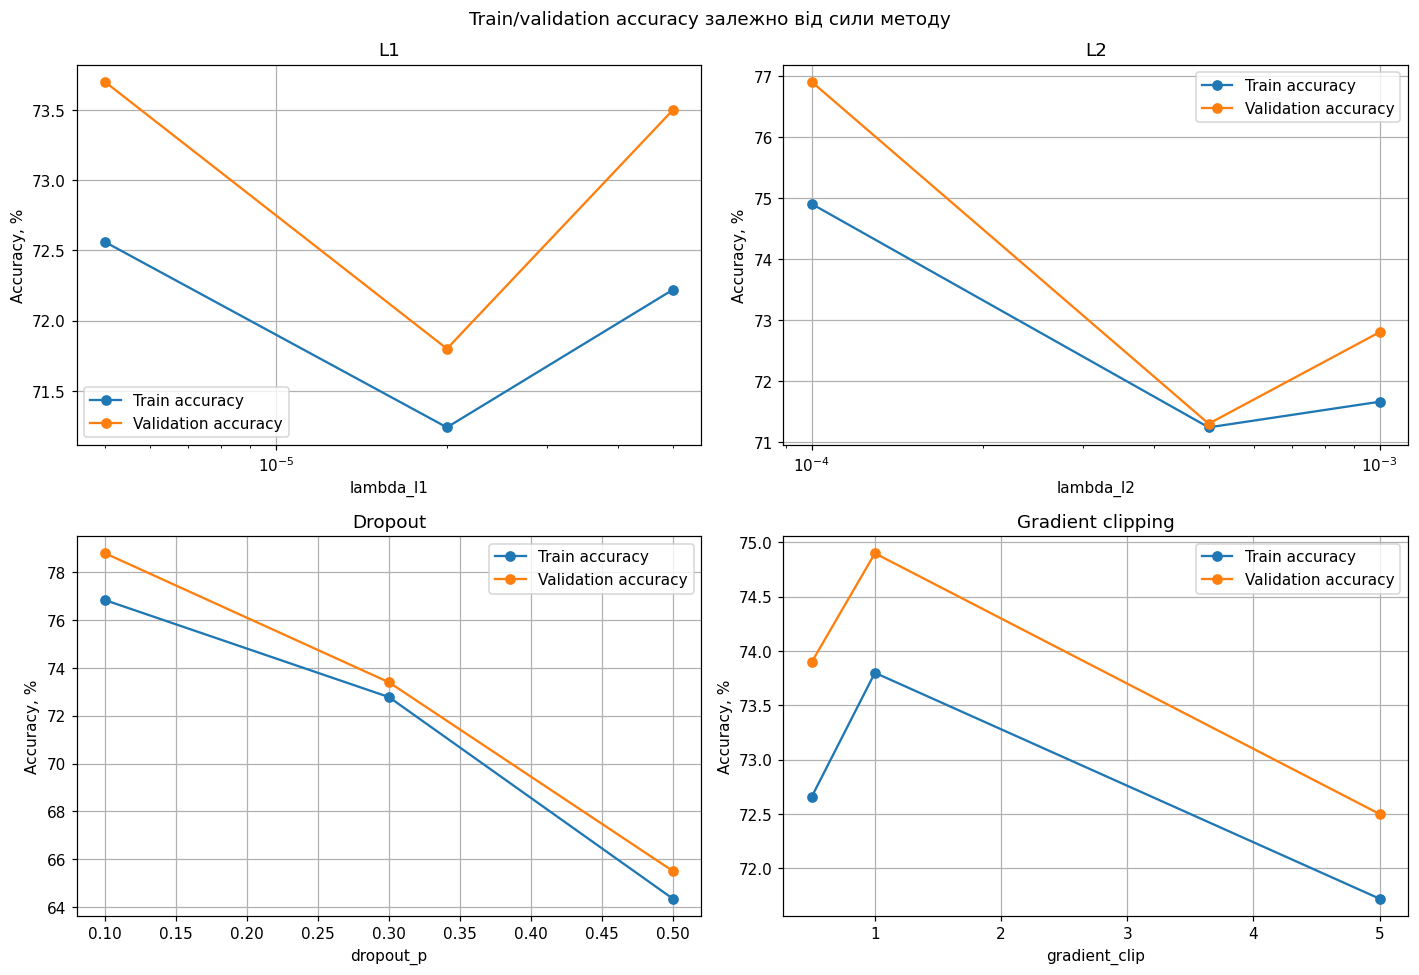

Порівняння найслабшого та найсильнішого налаштувань у кожному sweep:
L1: слабке=5e-06, val=0.7370, gap=-0.0114; сильне=5e-05, val=0.7350, gap=-0.0128
L2: слабке=0.0001, val=0.7690, gap=-0.0200; сильне=0.001, val=0.7280, gap=-0.0114
Dropout: слабке=0.1, val=0.7880, gap=-0.0196; сильне=0.5, val=0.6550, gap=-0.0116
Gradient clipping: слабке=0.5, val=0.7390, gap=-0.0124; сильне=5.0, val=0.7250, gap=-0.0078
Менший train-validation gap може свідчити про менше перенавчання, але якщо одночасно знижується і train accuracy, це може бути ознакою недонавчання.


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sweep_groups = [
    ('L1', l1_experiment_names, 'lambda_l1', True),
    ('L2', l2_experiment_names, 'lambda_l2', True),
    ('Dropout', [dropout_experiment_names[p] for p in [0.1, 0.3, 0.5]], 'dropout_p', False),
    ('Gradient clipping', gradient_clip_experiment_names, 'gradient_clip', False)
]

for ax, (group_label, names, parameter, log_scale) in zip(axes.flat, sweep_groups):
    ordered_names = sorted(names, key=lambda name: results[name]['config'][parameter])
    x_values = [results[name]['config'][parameter] for name in ordered_names]
    train_values = [results[name]['train_accuracy'] * 100.0 for name in ordered_names]
    val_values = [results[name]['val_accuracy'] * 100.0 for name in ordered_names]
    ax.plot(x_values, train_values, marker='o', label='Train accuracy')
    ax.plot(x_values, val_values, marker='o', label='Validation accuracy')
    if log_scale:
        ax.set_xscale('log')
    ax.set_title(group_label)
    ax.set_xlabel(parameter)
    ax.set_ylabel('Accuracy, %')
    ax.legend()

plt.suptitle('Train/validation accuracy залежно від сили методу')
plt.tight_layout()
plt.show()

print('Порівняння найслабшого та найсильнішого налаштувань у кожному sweep:')
for group_label, names, parameter, _ in sweep_groups:
    ordered_names = sorted(names, key=lambda name: results[name]['config'][parameter])
    weakest = results[ordered_names[0]]
    strongest = results[ordered_names[-1]]
    weak_gap = weakest['train_accuracy'] - weakest['val_accuracy']
    strong_gap = strongest['train_accuracy'] - strongest['val_accuracy']
    print(
        f'{group_label}: слабке={weakest["config"][parameter]}, '
        f'val={weakest["val_accuracy"]:.4f}, gap={weak_gap:.4f}; '
        f'сильне={strongest["config"][parameter]}, '
        f'val={strongest["val_accuracy"]:.4f}, gap={strong_gap:.4f}'
    )
print('Менший train-validation gap може свідчити про менше перенавчання, але '
      'якщо одночасно знижується і train accuracy, це може бути ознакою недонавчання.')

## Етап 14. Гістограми розподілу ваг

Для кожного основного методу будуються гістограми ваг **усіх трьох прихованих шарів**. На кожному графіку зіставляються:

- початковий розподіл після He initialization;
- розподіл після базового навчання без регуляризації;
- розподіл після відповідного методу.

Це дозволяє побачити, чи концентрує L1 ваги біля нуля, чи стискає L2 великі значення, та чи з'являються піки біля `-1` і `1` після weight clipping.

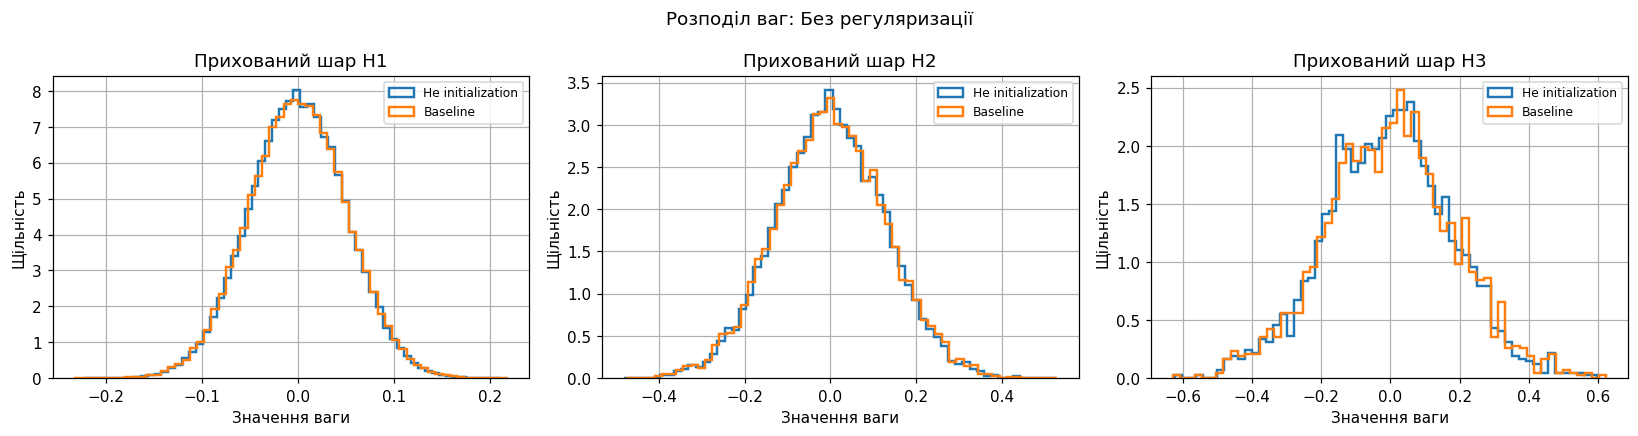

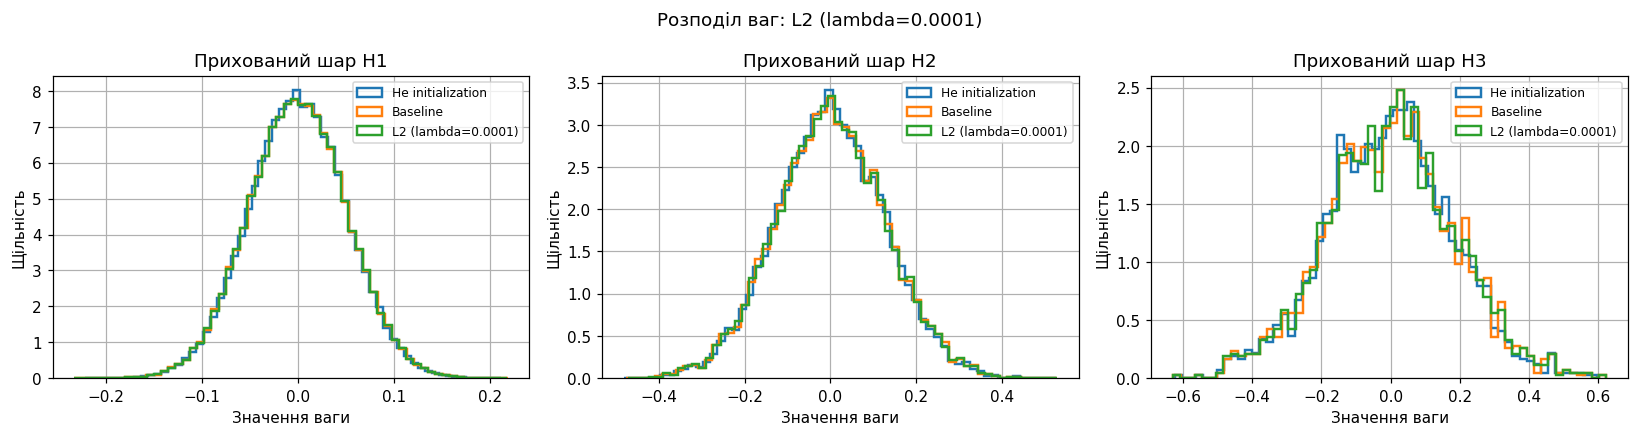

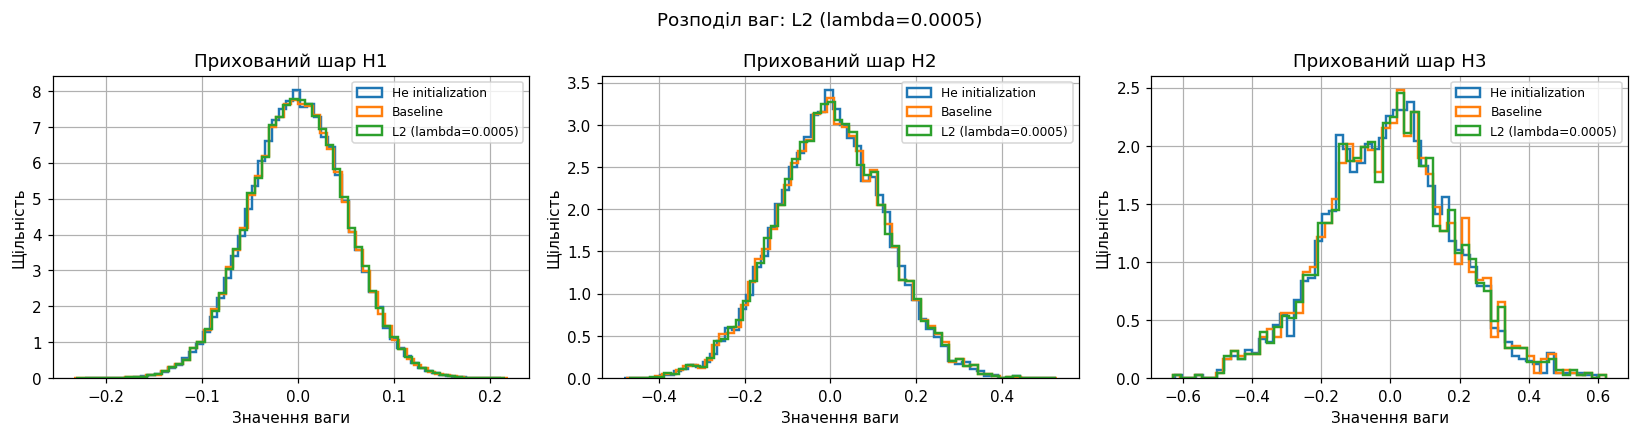

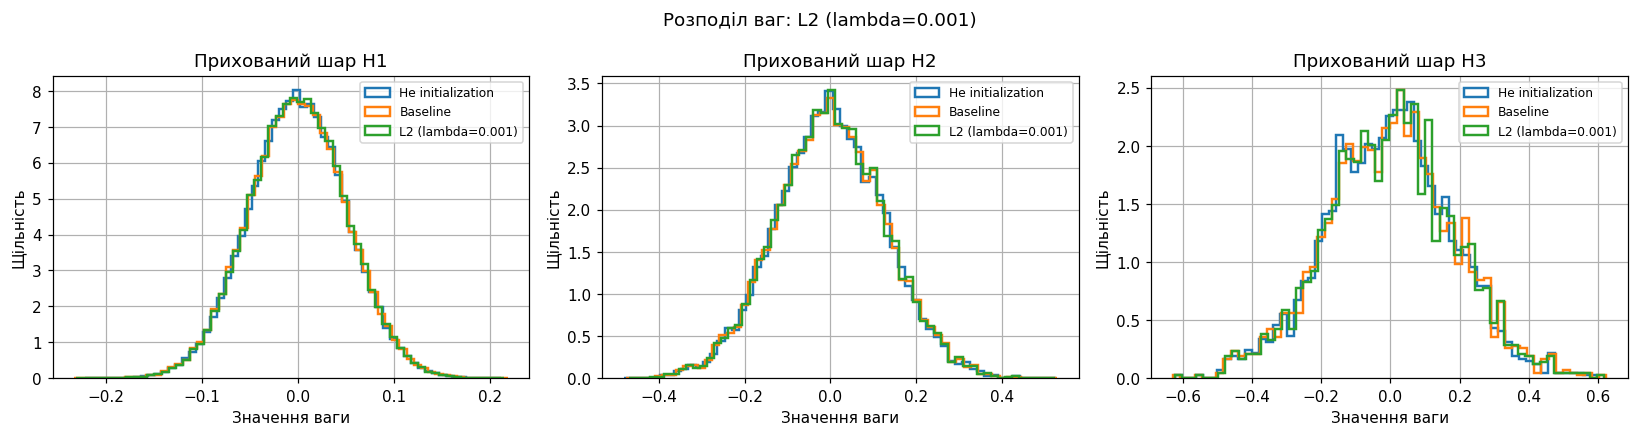

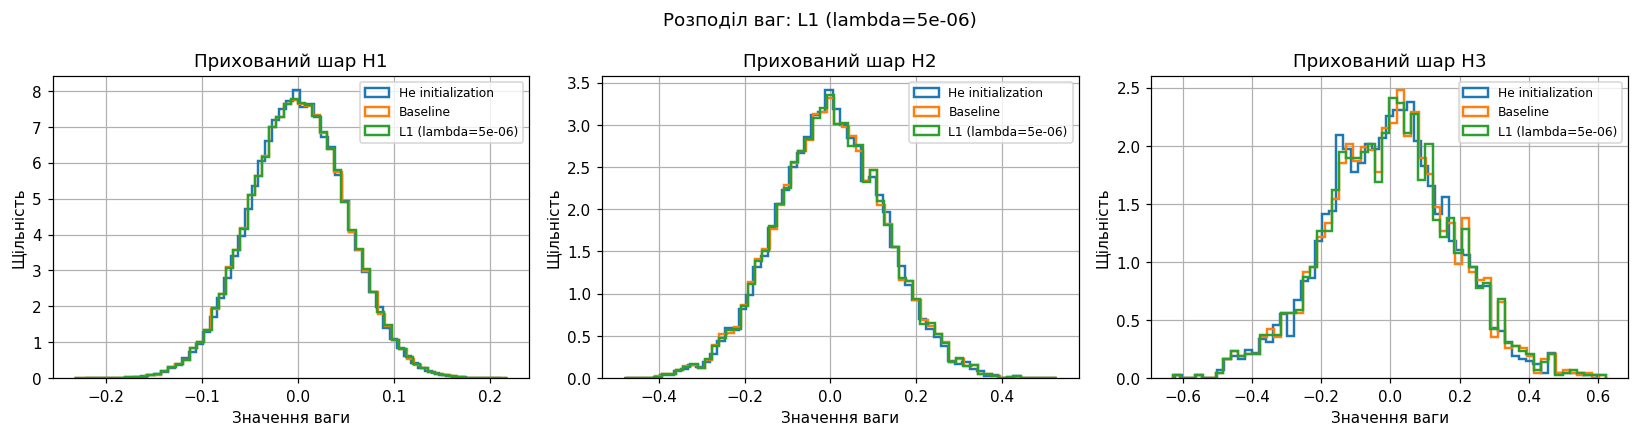

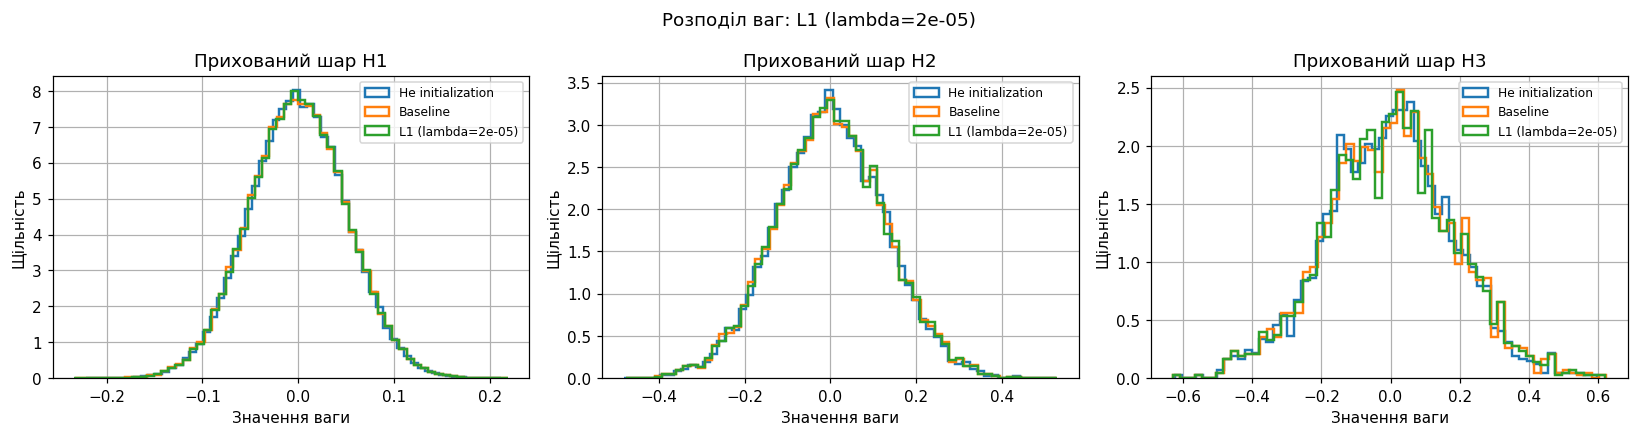

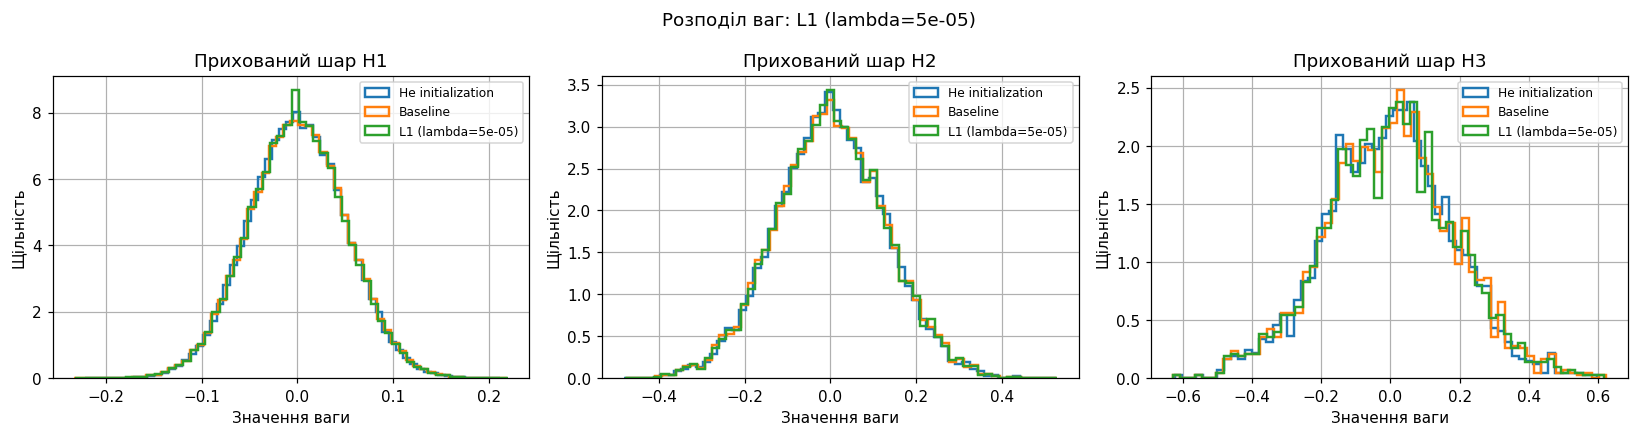

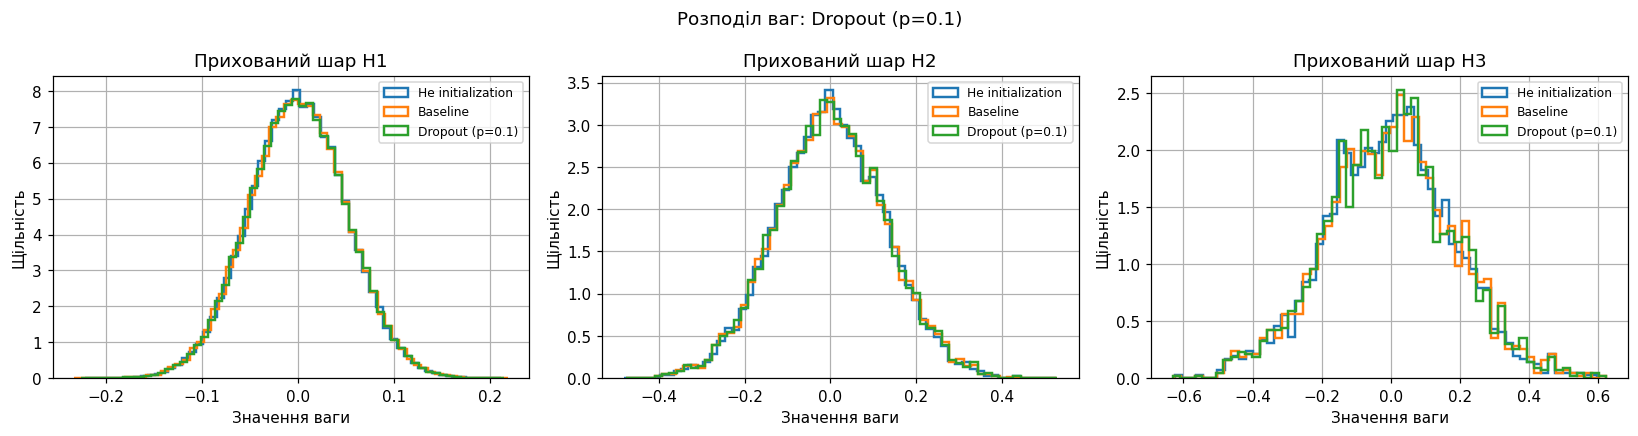

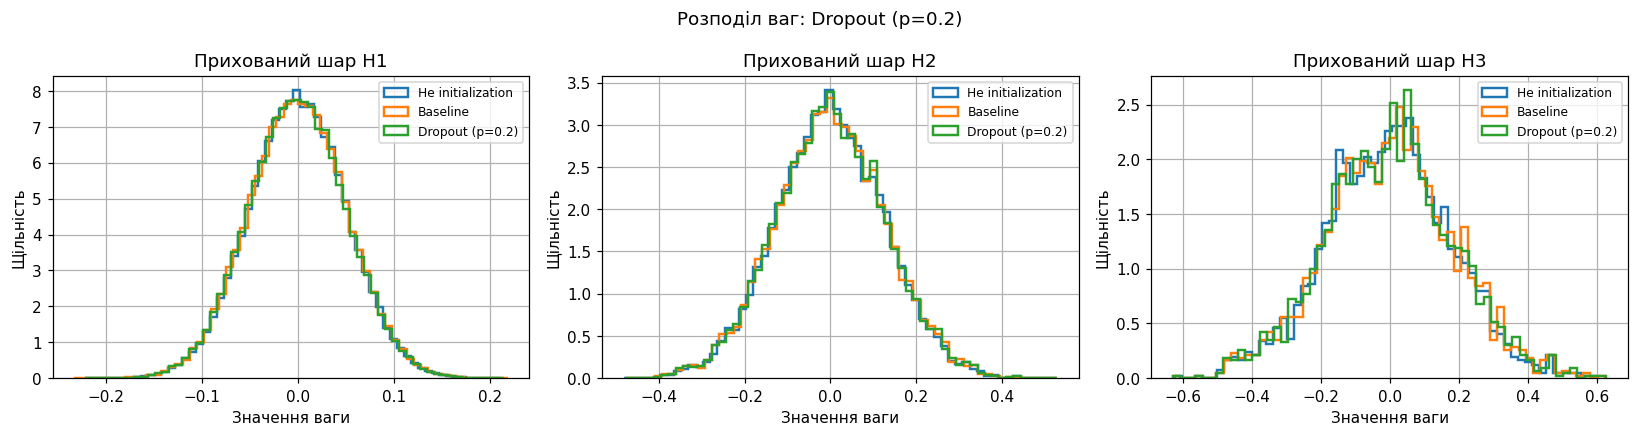

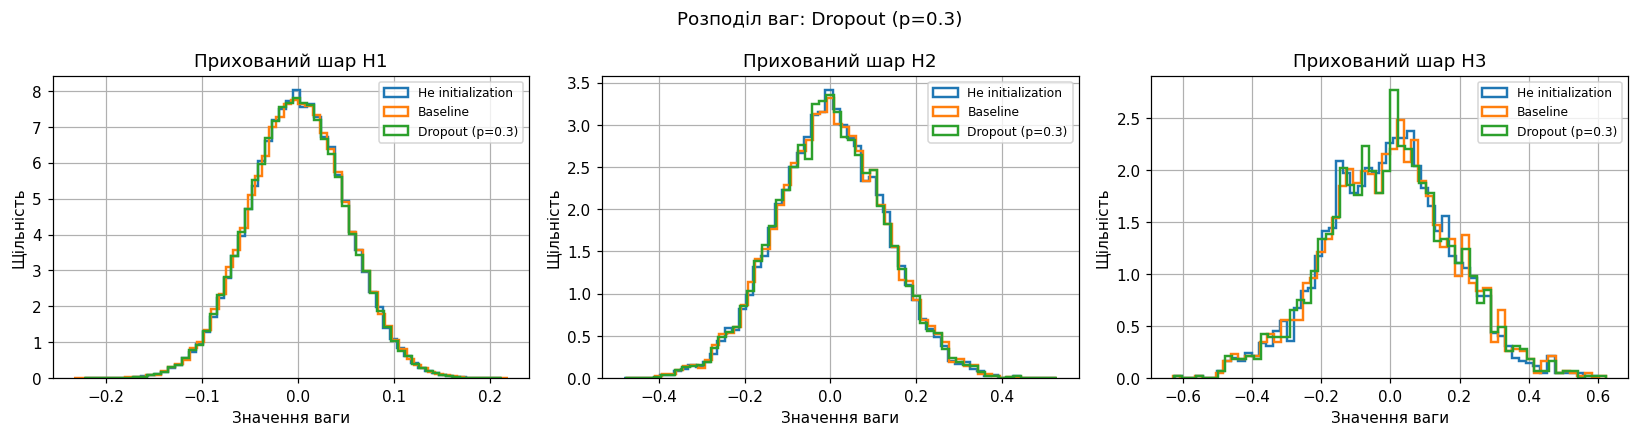

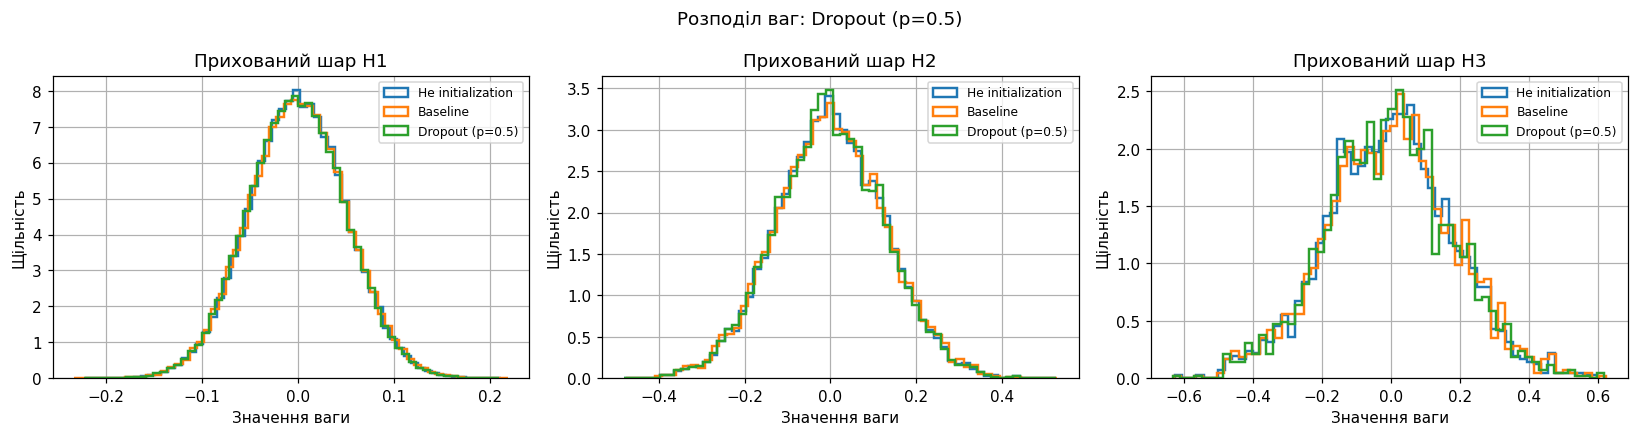

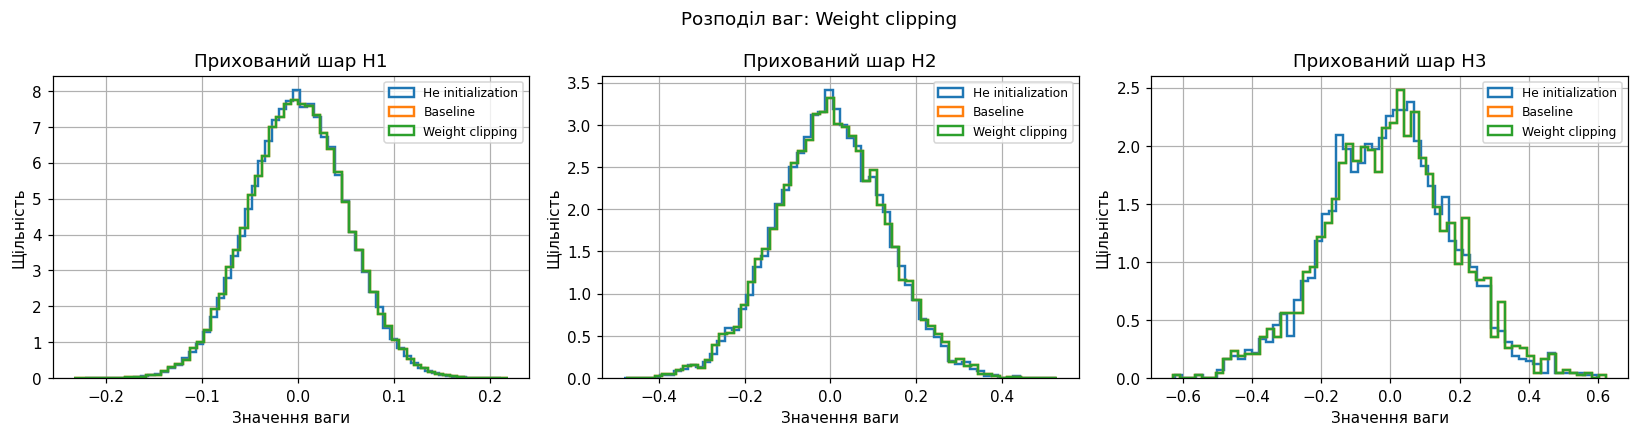

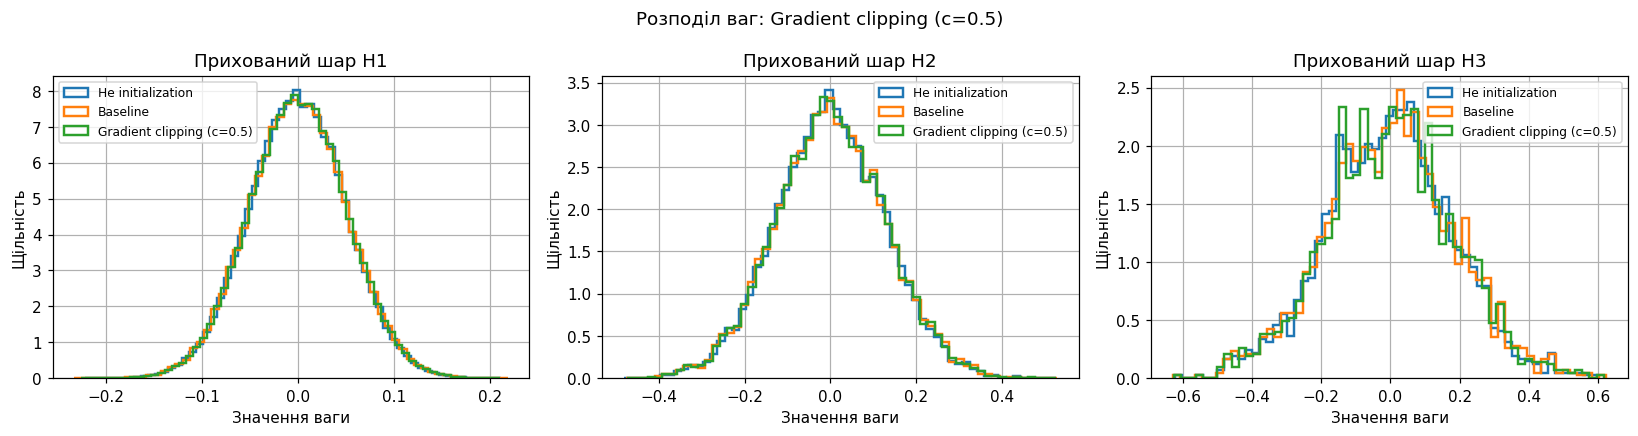

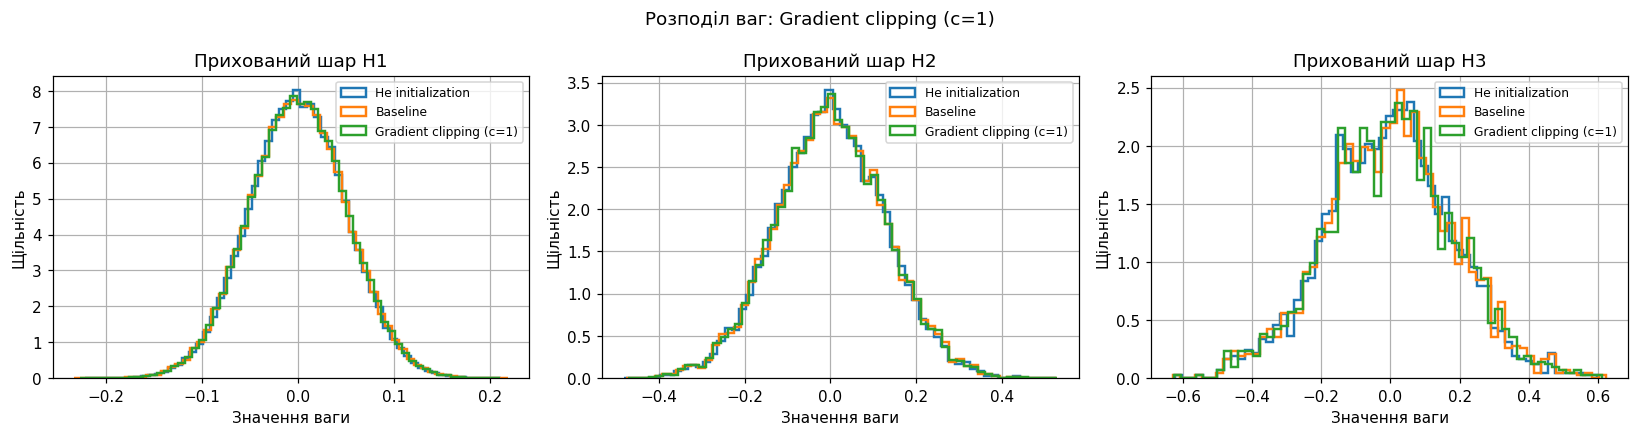

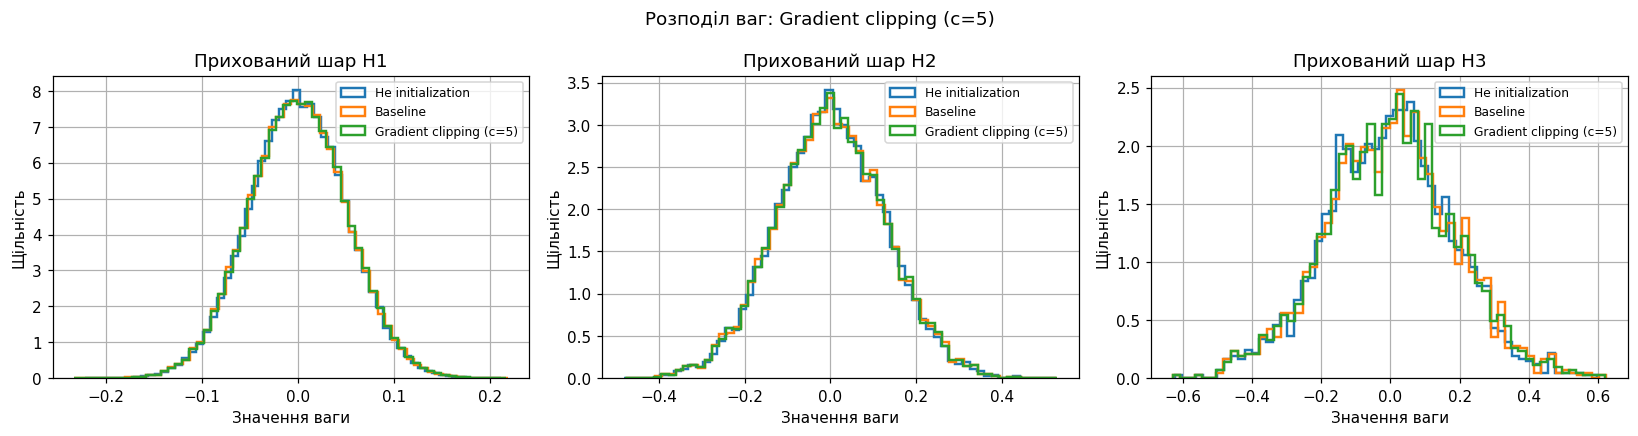

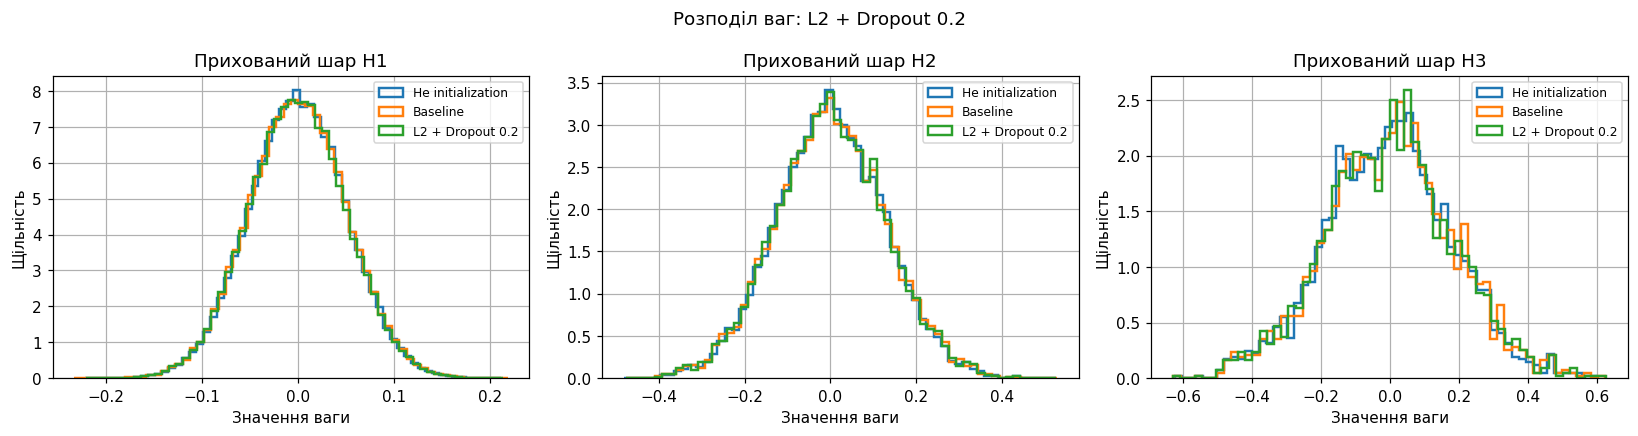

In [20]:
def plot_weight_distributions(method_label, result_name, bins=60):
    model = results[result_name]['model']
    hidden_weight_count = len(ARCHITECTURE) - 2
    fig, axes = plt.subplots(1, hidden_weight_count, figsize=(15, 4))

    for layer_index, ax in enumerate(np.atleast_1d(axes)):
        ax.hist(
            initial_weights[layer_index].ravel(), bins=bins, density=True,
            histtype='step', linewidth=1.6, label='He initialization'
        )
        ax.hist(
            baseline_model.weights[layer_index].ravel(), bins=bins, density=True,
            histtype='step', linewidth=1.6, label='Baseline'
        )
        if result_name != 'Без регуляризації':
            ax.hist(
                model.weights[layer_index].ravel(), bins=bins, density=True,
                histtype='step', linewidth=1.6, label=method_label
            )
        ax.set_title(f'Прихований шар H{layer_index + 1}')
        ax.set_xlabel('Значення ваги')
        ax.set_ylabel('Щільність')
        ax.legend(fontsize=8)

    fig.suptitle(f'Розподіл ваг: {method_label}')
    plt.tight_layout()
    plt.show()


# Будуємо гістограми для кожної конфігурації, включно з усіма значеннями lambda та c.
for result_name in results:
    plot_weight_distributions(result_name, result_name)

### Аналіз меж weight clipping та історії gradient clipping

Перевіряється кількість ваг, які досягли `-1` або `1`, а також кількість мінібатчів, у яких градієнт було обрізано. Це відображає різницю між обмеженням параметрів і обмеженням кроку оновлення.

In [21]:
weight_clip_result = results['Weight clipping']
print('Кількість ваг на межах -1 або 1:', weight_clip_result['weights_at_bounds'])
print('Частка ваг на межах, %:',
      weight_clip_result['weights_at_bounds'] /
      sum(W.size for W in weight_clip_result['model'].weights) * 100.0)

clip_diagnostics = []
for name in gradient_clip_experiment_names:
    result = results[name]
    clip_diagnostics.append({
        'Метод': name,
        'Середня норма градієнта за епохами': np.mean(result['history']['mean_gradient_norm']),
        'Обрізаних мінібатчів за всі епохи': np.sum(result['history']['clipped_batches'])
    })
display(pd.DataFrame(clip_diagnostics).round(4))

Кількість ваг на межах -1 або 1: 0
Частка ваг на межах, %: 0.0


,Метод,Середня норма градієнта за епохами,Обрізаних мінібатчів за всі епохи
0,Gradient clipping (c=0.5),1.6799,100
1,Gradient clipping (c=1),2.3843,100
2,Gradient clipping (c=5),2.0285,1


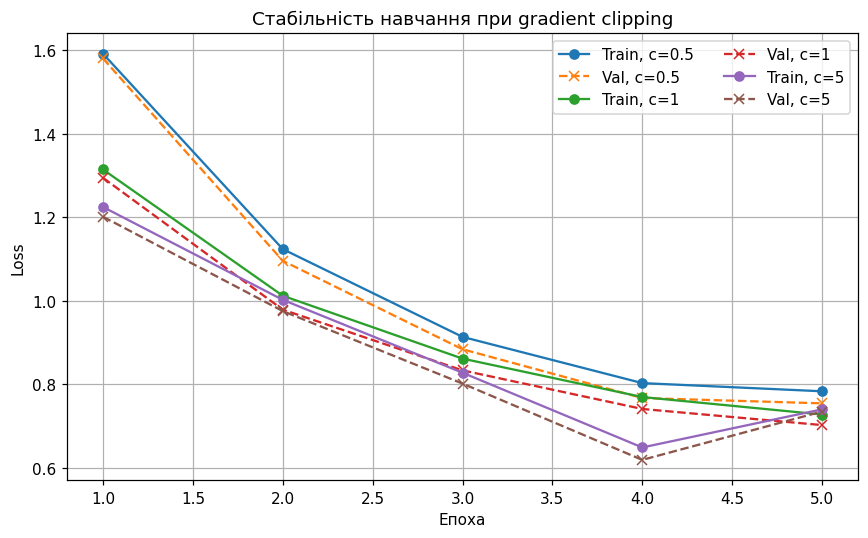

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in gradient_clip_experiment_names:
    history = results[name]['history']
    c_value = results[name]['config']['gradient_clip']
    ax.plot(epoch_numbers, history['train_loss'], marker='o', label=f'Train, c={c_value:g}')
    ax.plot(epoch_numbers, history['val_loss'], marker='x', linestyle='--', label=f'Val, c={c_value:g}')
ax.set_title('Стабільність навчання при gradient clipping')
ax.set_xlabel('Епоха')
ax.set_ylabel('Loss')
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## Етап 15. Залежність dead neurons від validation accuracy

На діаграмі розсіювання кожна точка відповідає одному з дев'яти основних експериментів. По осі X відкладається частка мертвих нейронів, по осі Y — validation accuracy. Це дає змогу дослідити, чи пов'язана кількість dead neurons з якістю класифікації.

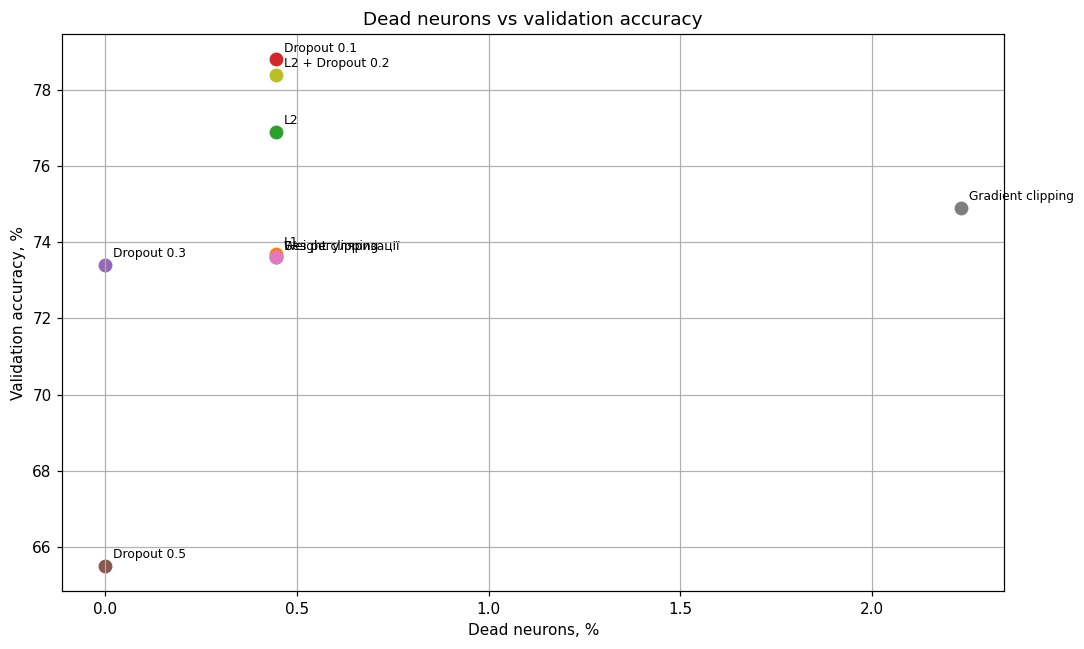

Кореляція Пірсона між dead neurons та validation accuracy: 0.25910392972597224
Увага: кореляція за дев’ятьма експериментами є описовою і не доводить причинно-наслідковий зв’язок.


In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
for method_label, result_name in summary_map.items():
    result = results[result_name]
    ax.scatter(result['dead_pct'], result['val_accuracy'] * 100.0, s=65)
    ax.annotate(
        method_label,
        (result['dead_pct'], result['val_accuracy'] * 100.0),
        xytext=(5, 5), textcoords='offset points', fontsize=8
    )

ax.set_title('Dead neurons vs validation accuracy')
ax.set_xlabel('Dead neurons, %')
ax.set_ylabel('Validation accuracy, %')
plt.tight_layout()
plt.show()

x_dead = np.array([results[name]['dead_pct'] for name in summary_map.values()])
y_accuracy = np.array([results[name]['val_accuracy'] * 100.0 for name in summary_map.values()])
if np.std(x_dead) > 0 and np.std(y_accuracy) > 0:
    dead_accuracy_correlation = float(np.corrcoef(x_dead, y_accuracy)[0, 1])
else:
    dead_accuracy_correlation = np.nan
print('Кореляція Пірсона між dead neurons та validation accuracy:', dead_accuracy_correlation)
print('Увага: кореляція за дев’ятьма експериментами є описовою і не доводить причинно-наслідковий зв’язок.')

## Етап 16. Аналіз результатів і відповіді на дослідницькі питання

### Чи завжди сильніша регуляризація покращує узагальнювальну здатність?

Ні. Помірна регуляризація може зменшити перенавчання, обмежуючи надмірно великі або складні параметри моделі. Однак надто сильна регуляризація обмежує здатність мережі описувати закономірності даних і призводить до недонавчання. Тому найкраще значення коефіцієнта залежить від даних, архітектури, швидкості навчання та інших параметрів.

### Як інтерпретувати зв'язок dead neurons і точності?

1. Велика кількість мертвих нейронів може зменшувати ефективну місткість мережі, але не обов'язково автоматично знижує точність.
2. Моделі з однаковою часткою dead neurons можуть мати різну точність: важливо, які саме нейрони залишилися активними та які ознаки вони навчилися представляти.
3. Sparsity ваг і dead neurons — різні характеристики. Малі ваги не означають, що нейрон завжди неактивний.
4. Оптимальний баланс визначається спільно за validation accuracy/loss, sparsity та dead neurons, а не за однією метрикою.

### Різниця між поняттями

- **Мала величина ваги** — вага близька до нуля, але не обов'язково дорівнює нулю.
- **Нульова або майже нульова вага** — окремий параметр зв'язку, модуль якого дорівнює нулю або менший за поріг `0.01`.
- **Неактивний нейрон для одного об'єкта** — його ReLU-вихід на конкретному прикладі дорівнює нулю.
- **Мертвий нейрон** — його передактивація не була додатною для жодного об'єкта всієї досліджуваної тренувальної підмножини.
- **Надмірно регуляризована модель** — модель, параметри якої обмежені настільки сильно, що вона не може достатньо добре апроксимувати дані; це зазвичай проявляється низькою якістю і на train, і на validation.

In [24]:
# Автоматичний аналіз отриманих числових результатів.
best_method_label = max(
    summary_map,
    key=lambda label: results[summary_map[label]]['val_accuracy']
)
best_result = results[summary_map[best_method_label]]
most_sparse_label = max(
    summary_map,
    key=lambda label: results[summary_map[label]]['sparsity']
)
most_dead_label = max(
    summary_map,
    key=lambda label: results[summary_map[label]]['dead_pct']
)

baseline_result = results['Без регуляризації']
train_val_gap_baseline = baseline_result['train_accuracy'] - baseline_result['val_accuracy']
best_gap = best_result['train_accuracy'] - best_result['val_accuracy']

print('Найкраща validation accuracy серед основних методів:')
print(f"{best_method_label}: {best_result['val_accuracy'] * 100:.2f}%")
print(f"Validation loss: {best_result['val_loss']:.4f}")
print(f"Dead neurons: {best_result['dead_pct']:.2f}%")
print(f"Sparsity: {best_result['sparsity']:.2f}%")

print('\nНайбільша sparsity:')
print(f"{most_sparse_label}: {results[summary_map[most_sparse_label]]['sparsity']:.2f}%")
print('\nНайбільша частка dead neurons:')
print(f"{most_dead_label}: {results[summary_map[most_dead_label]]['dead_pct']:.2f}%")

print('\nРізниця train accuracy - validation accuracy:')
print(f'Без регуляризації: {train_val_gap_baseline * 100:.2f} відсоткових пунктів')
print(f'{best_method_label}: {best_gap * 100:.2f} відсоткових пунктів')

if best_result['val_accuracy'] > baseline_result['val_accuracy']:
    print('\nДля цієї конфігурації найкращий метод покращив validation accuracy відносно базового.')
elif best_result['val_accuracy'] < baseline_result['val_accuracy']:
    print('\nЖоден із вибраних основних методів не перевищив базову validation accuracy; '
          'для цих параметрів регуляризація могла бути надмірною або недостатньою.')
else:
    print('\nНайкращий метод має таку саму validation accuracy, як базова модель.')

if best_gap < train_val_gap_baseline:
    print('Різниця між train і validation accuracy зменшилася відносно базової моделі.')
else:
    print('Різниця між train і validation accuracy не зменшилася відносно базової моделі.')

print('\nКореляція dead neurons та validation accuracy:', dead_accuracy_correlation)
if np.isfinite(dead_accuracy_correlation):
    if dead_accuracy_correlation < -0.3:
        print('У цьому наборі експериментів спостерігається помірна/сильна обернена тенденція.')
    elif dead_accuracy_correlation > 0.3:
        print('У цьому наборі експериментів спостерігається додатна тенденція.')
    else:
        print('Лінійний зв’язок у цьому наборі експериментів слабкий.')
print('Висновок потрібно робити з урахуванням усіх таблиць і гістограм, а не лише кореляції.')

Найкраща validation accuracy серед основних методів:
Dropout 0.1: 78.80%
Validation loss: 0.6434
Dead neurons: 0.45%
Sparsity: 14.53%

Найбільша sparsity:
Dropout 0.5: 14.63%

Найбільша частка dead neurons:
Gradient clipping: 2.23%

Різниця train accuracy - validation accuracy:
Без регуляризації: -0.96 відсоткових пунктів
Dropout 0.1: -1.96 відсоткових пунктів

Для цієї конфігурації найкращий метод покращив validation accuracy відносно базового.
Різниця між train і validation accuracy зменшилася відносно базової моделі.

Кореляція dead neurons та validation accuracy: 0.25910392972597224
Лінійний зв’язок у цьому наборі експериментів слабкий.
Висновок потрібно робити з урахуванням усіх таблиць і гістограм, а не лише кореляції.


## Загальний висновок

У роботі реалізовано повнозв'язну нейронну мережу з трьома прихованими шарами на основі матричних операцій NumPy. Прямий прохід, Softmax, categorical cross-entropy, backpropagation, похідна ReLU, SGD, He initialization, Dropout, L1/L2 та обидва типи clipping реалізовано без використання автоматичного диференціювання або готових нейромережевих модулів.

Правильність backpropagation перевіряється чисельним диференціюванням, а механізм збереження/відновлення — порівнянням вихідних ймовірностей двох екземплярів моделі. У другому блоці результати всіх методів порівнюються за validation accuracy, validation loss, sparsity та часткою мертвих нейронів. Остаточні числові висновки формуються автоматично з фактично отриманих результатів запуску.

**Важливо для інтерпретації:** висока sparsity не гарантує високої точності, а dead neurons не є тотожними нульовим вагам. Посилення регуляризації може зменшити перенавчання, але за надмірного значення параметра здатне спричинити недонавчання.